# 🎙️ SHL Grammar Scoring Engine
### Spoken English audio (45–60 s) → continuous grammar score (0–5)

| | |
|---|---|
| **Task** | Predict the MOS Likert grammar score a human rater would give (SHL rubric 1–5; 0 = not assessable) |
| **Data** | 769 labelled training clips · 216 test clips (`.wav`) |
| **Leaderboard metric** | Pearson correlation and RMSE, combined as 0.6 · RMSE + 0.4 · (1 − Pearson), lower is better |
| **Runs from** | Raw audio only. No external data, no manual labels, ~2.5 h on one T4 GPU |

### Final results
| | RMSE | Pearson | MAE |
|---|---|---|---|
| **Train (in-sample)** | **0.1425** | 0.9908 | 0.1067 |
| **CV** (5-fold speaker-grouped, mean of 3 seeds) | **0.5203** | **0.8584** | 0.4017 |
| **Public leaderboard** | **0.3464** (this notebook) · best 0.3429 (same architecture) | | |

## Pipeline
```
                 ┌──────────────────────────────────────────────┐
  Audio clip ──► │ SNR gate (signal processing)                 │── SNR < 4 dB ──► score 0 (not assessable)
                 └──────────────────────────────────────────────┘
                        │ assessable
        ┌───────────────┼───────────────────────┬──────────────────────────┐
        ▼               ▼                       ▼                          ▼
  Whisper-large-v3   Whisper encoder        HuBERT-large              Hand-built speech
  speech-to-text     embedding              15 s segment embeddings   features (from scratch)
        │            (pretrained DL)        (pretrained DL)
        ▼
  Transcript ──► NLP: Qwen3-4B grammar correction + rubric judge · spaCy syntax · Qwen text embeddings
        │
        ▼
  ML heads: SVR ×4 · Ridge ×2 · LightGBM   +   from-scratch PyTorch fusion network
        │
        ▼
  Non-negative linear stack (trained on speaker-grouped out-of-fold predictions) ──► score 1–5
```

## Contents
1. Setup
2. Data & exploratory analysis
3. Assessability gate (signal processing)
4. Speech-to-text (Whisper)
5. Hand-built speech features + spaCy syntax features
6. NLP: LLM grammar correction & rubric judge
7. Pretrained deep representations (Whisper encoder, HuBERT, Qwen)
8. From-scratch deep learning (PyTorch fusion network)
9. ML heads + speaker-grouped stacking: CV, **Train RMSE**, Pearson
10. Ablation: what each component contributes
11. Overfitting & robustness checks
12. Grammar feedback demo + `score_audio()` for any new audio file
13. Submission file (validated against `sample_submission.csv`)
14. Report: approach, preprocessing, architecture, results, what didn't work, licences

## 1. Setup

**What this section does**
1. Installs the two libraries Kaggle does not ship by default.
2. Imports everything, fixes random seeds, loads the three CSV files and finds every audio file.
3. Defines two helpers used throughout: `checkpoint()` and the evaluation metrics.

**Why these libraries**
| Library | Used for | Why this one |
|---|---|---|
| `faster-whisper` | Speech-to-text | Same Whisper model, ~4× faster (CTranslate2 engine), built-in voice-activity detection |
| spaCy `en_core_web_sm` | Part-of-speech tags, dependency parses | Fast, accurate, standard NLP toolkit |

**Competition rules enforced by this notebook**
| Rule | How we comply |
|---|---|
| No external data | Models are trained only on the 769 provided training clips |
| No hand labelling of test data | Test clips are never listened to or labelled; `test.csv` labels are random and are dropped on load |
| Open-source code only (OSI licence, commercial use allowed) | Whisper, faster-whisper, spaCy, LightGBM (MIT) · HuBERT, Qwen3 (Apache-2.0) · PyTorch, scikit-learn (BSD) · librosa (ISC) |
| Competition data is not redistributed | Outputs stay in `/kaggle/working`; no audio, labels or transcripts leave Kaggle |
| Exact submission format | Column names come from `sample_submission.csv`; rows = all 216 files in `test.csv` (the sample file lists only 204 — our 216-row submissions are accepted and scored by Kaggle) |

**Reproducibility**
- One global seed (`SEED = 42`) controls every random split and model.
- `checkpoint()` saves each slow result to `/kaggle/working/outputs/`. If the session restarts, re-running a cell reloads
  what *this notebook* already computed. Delete that folder to force a full rerun.

In [1]:
# ============================================================
# 1.1 Install libraries not pre-installed on Kaggle
# ============================================================
# faster-whisper : optimised Whisper inference (speech-to-text)
# en_core_web_sm : small English spaCy pipeline (POS tags + dependency parser)
!pip install -q faster-whisper
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 15.2 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 57.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 MB 49.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 66.8 MB/s eta 0:00:00:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 85.9 MB/s eta 0:00:0000:010:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
# ============================================================
# 1.2 Imports, seeds, paths, data files, audio index, helpers
# ============================================================

# ---------- Standard library ----------
import gc
import glob
import json
import os
import random
import re
import time
import warnings
from pathlib import Path

# ---------- Scientific stack ----------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
import torch
from scipy.stats import pearsonr
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# ---------- Reproducibility ----------
SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Fix every random number generator we use, so results are repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

# ---------- Hardware ----------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda", "No GPU found: Settings -> Accelerator -> GPU T4 x1"

# ---------- Paths ----------
# Competition data folder: the 'Dataset_Final' directory that contains train.csv
DATA_DIR = Path(next(p for p in glob.glob("/kaggle/input/**/train.csv", recursive=True)
                     if "Dataset_Final" in p)).parent

# Every file this notebook produces is written here
OUT = Path("/kaggle/working/outputs")
for sub_dir in ["transcripts", "features", "embeddings", "oof", "submissions", "plots"]:
    (OUT / sub_dir).mkdir(parents=True, exist_ok=True)

# ---------- CSV files ----------
train_df = pd.read_csv(DATA_DIR / "train.csv")                    # filename + true grammar label
test_raw = pd.read_csv(DATA_DIR / "test.csv")                     # filename + RANDOM label (per competition description)
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")      # official output format (columns + row order)

# Guard against leakage: keep only the filename column of test.csv; its labels are random noise.
test_df = test_raw[["filename"]].copy()

# ---------- Audio index: (split, filename) -> full path ----------
# A recursive search makes the notebook independent of the exact folder layout.
AUDIO = {}
for wav_path in glob.glob(str(DATA_DIR / "**" / "*.wav"), recursive=True):
    split = "test" if "test" in Path(wav_path).parent.as_posix().lower() else "train"
    AUDIO[(split, Path(wav_path).name)] = wav_path

# Every clip we process, in a fixed order: all train clips, then all test clips
ALL_CLIPS = [("train", f) for f in train_df.filename] + [("test", f) for f in test_df.filename]
missing = [clip for clip in ALL_CLIPS if clip not in AUDIO]


# ---------- Helper: checkpoint slow steps ----------
def checkpoint(path, compute_fn):
    """
    Return the result of `compute_fn()`, caching it on disk.

    - If `path` already exists (produced earlier by THIS notebook), load and return it.
    - Otherwise run `compute_fn()`, save the result to `path`, and return it.
    Supports pandas DataFrames (.csv) and NumPy arrays (.npy).
    """
    path = Path(path)
    if path.exists():
        print(f"↺ Loaded checkpoint: {path.name}")
        return pd.read_csv(path) if path.suffix == ".csv" else np.load(path, allow_pickle=True)

    start = time.time()
    result = compute_fn()
    if isinstance(result, pd.DataFrame):
        result.to_csv(path, index=False)
    else:
        np.save(path, result)
    print(f"✓ Computed and saved {path.name} in {(time.time() - start) / 60:.1f} min")
    return result


# ---------- Helper: evaluation metrics ----------
def rmse(y_true, y_pred) -> float:
    """Root mean squared error: penalises large mistakes more."""
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def mae(y_true, y_pred) -> float:
    """Mean absolute error: average size of a mistake, in score points."""
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


def lb_metric(y_true, y_pred) -> float:
    """Leaderboard metric: 0.6*RMSE + 0.4*(1 - Pearson). Lower is better."""
    return 0.6 * rmse(y_true, y_pred) + 0.4 * (1 - pearsonr(y_true, y_pred)[0])


# ---------- Environment report ----------
import faster_whisper, lightgbm, sklearn, spacy, transformers

gpu = torch.cuda.get_device_properties(0)
print(f"GPU          : {gpu.name} | {gpu.total_memory / 1e9:.1f} GB")
print(f"Versions     : torch {torch.__version__} | transformers {transformers.__version__} | "
      f"scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__} | "
      f"faster-whisper {faster_whisper.__version__} | spaCy {spacy.__version__}")
print(f"Data folder  : {DATA_DIR}")
print(f"train.csv    : {train_df.shape} {list(train_df.columns)}")
print(f"test.csv     : {test_raw.shape} {list(test_raw.columns)}  -> kept only 'filename' (labels are random)")
print(f"sample_sub   : {sample_sub.shape} {list(sample_sub.columns)} | same files as test.csv: "
      f"{set(sample_sub.iloc[:, 0]) == set(test_df.filename)}")
print(f"Audio files  : {len(AUDIO)} found | {len(missing)} missing {missing[:3]}")
print(f"Example path : {AUDIO[ALL_CLIPS[0]]}")

GPU          : Tesla T4 | 15.6 GB
Versions     : torch 2.11.0+cu128 | transformers 5.16.1 | scikit-learn 1.6.1 | lightgbm 4.6.0 | faster-whisper 1.2.1 | spaCy 3.8.16
Data folder  : /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
train.csv    : (769, 2) ['filename', 'label']
test.csv     : (216, 2) ['filename', 'label']  -> kept only 'filename' (labels are random)
sample_sub   : (204, 2) ['filename', 'label'] | same files as test.csv: False
Audio files  : 985 found | 0 missing []
Example path : /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_192.wav


## 2. Data & exploratory analysis

**What:** inspect the labels, the audio format and the train/test split before any modelling.

**Why:**
- The **label distribution** shows which score bands are rare (and therefore harder to predict).
- The **duration** comparison checks whether train and test come from the same distribution; a mismatch changes how features must be built.
- The **file-list check** confirms exactly which clips must be scored.

**How:** read each file's header with `soundfile.info` (no decoding, so it takes seconds), then summarise and plot.

test.csv files: 216 | sample_submission files: 204 | in both: 25 | only in test.csv: 191 | only in sample: 179
-> The submission will contain all 216 test.csv files, with sample_submission's column format.

Train label distribution:
label  0.0  1.0  1.5  2.0  2.5  3.0  3.5  4.0  4.5  5.0
clips   37    1    3  102   79  174   64  124   52  133
Mean 3.31 | std 1.24 | label 0 (not assessable): 37 clips

Duration (seconds):
       count  mean  std   min   25%   50%   75%   max
split                                                
test   216.0  48.8  8.2   6.5  45.1  45.1  60.0  61.0
train  769.0  55.8  7.9  20.1  54.2  60.1  60.1  61.0

Original sample rates: {16000: 985}
Channels             : {1: 985}


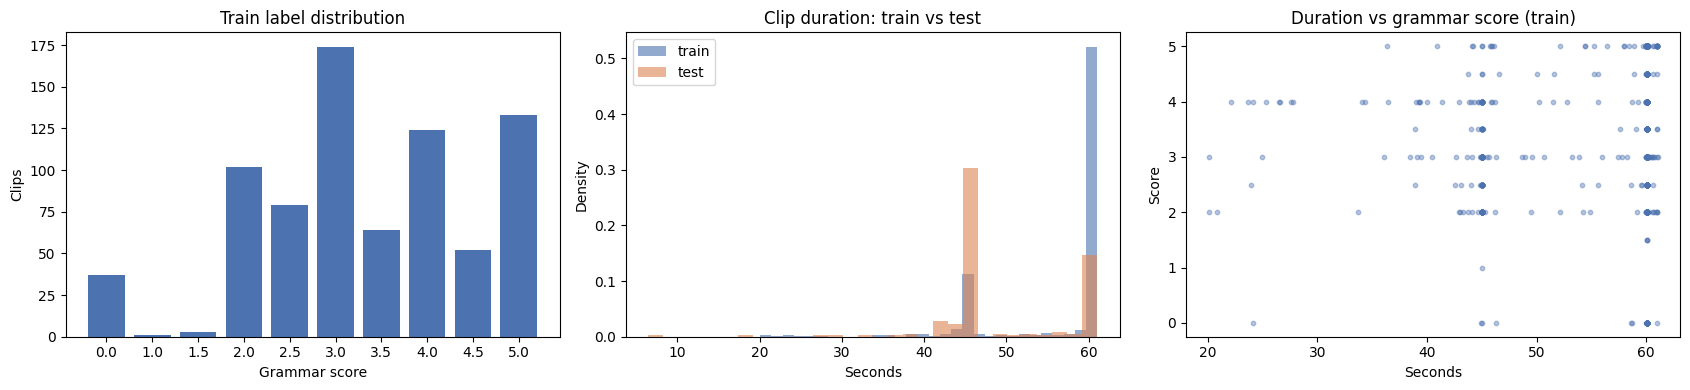

In [3]:
# ============================================================
# 2. Data & exploratory analysis
# ============================================================

def header_info(path: str) -> dict:
    """Read duration / sample rate / channels from the wav header (no audio decoding)."""
    info = sf.info(path)
    return {"duration": info.duration, "orig_sr": info.samplerate, "channels": info.channels}


# ---------- One metadata row per clip (train + test, fixed order) ----------
meta = pd.DataFrame([{"split": s, "filename": f, **header_info(AUDIO[(s, f)])} for s, f in ALL_CLIPS])
meta = meta.merge(train_df, on="filename", how="left")       # true labels for train clips
meta.loc[meta.split == "test", "label"] = np.nan             # test labels are unknown

# ---------- Which files must be scored? ----------
test_set, sample_set = set(test_df.filename), set(sample_sub.filename)
print(f"test.csv files: {len(test_set)} | sample_submission files: {len(sample_set)} | "
      f"in both: {len(test_set & sample_set)} | only in test.csv: {len(test_set - sample_set)} | "
      f"only in sample: {len(sample_set - test_set)}")
print("-> The submission will contain all 216 test.csv files, with sample_submission's column format.\n")

# ---------- Labels ----------
counts = train_df.label.value_counts().sort_index()
print("Train label distribution:")
print(counts.to_frame("clips").T.to_string())
print(f"Mean {train_df.label.mean():.2f} | std {train_df.label.std():.2f} | "
      f"label 0 (not assessable): {(train_df.label == 0).sum()} clips\n")

# ---------- Audio format ----------
print("Duration (seconds):")
print(meta.groupby("split").duration.describe().round(1).to_string())
print("\nOriginal sample rates:", meta.orig_sr.value_counts().to_dict())
print("Channels             :", meta.channels.value_counts().to_dict())

# ---------- Plots ----------
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

ax[0].bar(counts.index.astype(str), counts.values, color="#4C72B0")
ax[0].set(title="Train label distribution", xlabel="Grammar score", ylabel="Clips")

for split, color in [("train", "#4C72B0"), ("test", "#DD8452")]:
    ax[1].hist(meta[meta.split == split].duration, bins=30, alpha=0.6, density=True, label=split, color=color)
ax[1].set(title="Clip duration: train vs test", xlabel="Seconds", ylabel="Density")
ax[1].legend()

tr = meta[meta.split == "train"]
ax[2].scatter(tr.duration, tr.label, s=10, alpha=0.4, color="#4C72B0")
ax[2].set(title="Duration vs grammar score (train)", xlabel="Seconds", ylabel="Score")

plt.tight_layout()
plt.savefig(OUT / "plots/01_eda.png", dpi=120)
plt.show()

**Result**
- **`sample_submission.csv` is from a different test set**: only 25 of its 204 files appear in `test.csv`. We use it only for the
  column format; the submission covers all 216 `test.csv` files (Kaggle scores these files).
- **Length mismatch**: train clips are mostly 60 s (median 60.1 s), test clips mostly 45 s (median 45.1 s, min 6.5 s).
  → features must be *rates* (per minute / per 100 words), not counts, and audio embeddings are computed on fixed **15 s segments**.
- **Labels**: concentrated in 2–5 (peak at 3.0, 174 clips); scores 1.0–1.5 have only 4 clips, so the low end is hard to learn.
  37 clips are labelled 0 (not assessable) → handled by a separate rule (Section 3).
- **Format**: every file is already 16 kHz mono, so loading needs no resampling (librosa still enforces it for safety).
- Duration shows no clear relation to the score → clip length is not a grammar signal.

## 3. Assessability gate (signal processing)

**What:** decide whether a clip contains assessable speech. If it does not, predict **0**.

**Why:** score 0 means "not assessable" (noise / no speech). These 37 clips (~5 %) are too few for a model to learn,
but they are separable by **signal-to-noise ratio**. A rule is more reliable and fully explainable. The grammar models
are then trained only on assessable clips, so noise clips cannot distort them.

**How (this audio preprocessing is reused by every later section):**
1. Load audio with librosa → **16 kHz mono float32**, the input every speech model below expects.
2. Split into 25 ms frames (10 ms hop) and compute each frame's energy.
3. Ignore *digital silence* (near-exact zeros, e.g. padding), which would otherwise fake a perfect noise floor.
4. SNR = 10·log₁₀( 90th-percentile energy / 10th-percentile energy ): speech level vs background floor, clipped to 0–60 dB.
5. Gate: **SNR < 4 dB → not assessable**, verified against the training labels below.

✓ Computed and saved signal_stats.csv in 1.2 min
Gate vs true label (train):
col_0      assessable  gated -> 0
row_0                            
label = 0           0          37
label > 0         731           1

SNR of label-0 clips : min 2.5 | max 3.9 dB
SNR of label>0 clips : min 2.8 | 5th pct 21.3 dB
Test clips gated     : 0 of 216


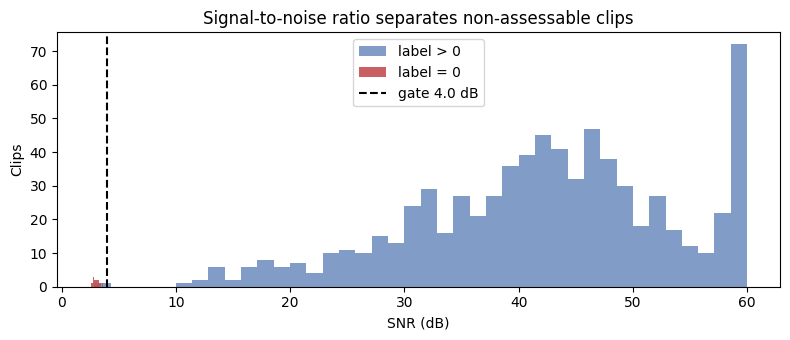

In [4]:
# ============================================================
# 3. Audio loading + signal statistics + SNR gate
# ============================================================
SR = 16_000                 # target sample rate for all speech models
FRAME, HOP = 400, 160       # 25 ms frames, 10 ms hop at 16 kHz
SNR_GATE_DB = 4.0           # clips below this SNR are "not assessable"


def load_audio(path: str, sr: int = SR) -> np.ndarray:
    """Load any wav as mono float32 at `sr` Hz (librosa resamples and down-mixes if needed)."""
    audio, _ = librosa.load(path, sr=sr, mono=True)
    return audio.astype(np.float32)


def signal_stats(audio: np.ndarray) -> dict:
    """Frame-energy statistics: RMS, SNR (dB), voiced-frame ratio, digital-silence fraction."""
    frames = librosa.util.frame(np.pad(audio, (0, FRAME)), frame_length=FRAME, hop_length=HOP)
    energy = (frames.astype(np.float64) ** 2).mean(axis=0)
    digital = np.abs(frames).max(axis=0) < 1e-4                    # near-exact zeros (padding)
    e = energy[~digital]
    if len(e) < 10:                                                # essentially empty file
        return {"rms": 0.0, "snr_db": 0.0, "voiced_ratio": 0.0, "digital_silence_frac": float(digital.mean())}
    noise_floor = np.percentile(e, 10) + 1e-12
    speech_level = np.percentile(e, 90) + 1e-12
    return {
        "rms": float(np.sqrt(np.mean(audio ** 2))),
        "snr_db": float(np.clip(10 * np.log10(speech_level / noise_floor), 0, 60)),
        "voiced_ratio": float((e > noise_floor * 10 ** 0.6).mean()),   # frames > 6 dB above the floor
        "digital_silence_frac": float(digital.mean()),
    }


def compute_signal_table() -> pd.DataFrame:
    """Signal statistics for every clip (train + test)."""
    rows = [{"split": s, "filename": f, **signal_stats(load_audio(AUDIO[(s, f)]))}
            for s, f in tqdm(ALL_CLIPS, desc="signal stats")]
    return pd.DataFrame(rows)


sig = checkpoint(OUT / "features/signal_stats.csv", compute_signal_table)
meta = meta.drop(columns=[c for c in sig.columns if c in meta.columns and c not in ("split", "filename")])
meta = meta.merge(sig, on=["split", "filename"])
meta["assessable"] = (meta.snr_db >= SNR_GATE_DB).astype(int)
assert len(meta) == len(ALL_CLIPS)

# ---------- Verify the gate against training labels ----------
tr = meta[meta.split == "train"]
is_zero = tr.label == 0
print("Gate vs true label (train):")
print(pd.crosstab(np.where(is_zero, "label = 0", "label > 0"),
                  np.where(tr.assessable == 0, "gated -> 0", "assessable")).to_string())
print(f"\nSNR of label-0 clips : min {tr[is_zero].snr_db.min():.1f} | max {tr[is_zero].snr_db.max():.1f} dB")
print(f"SNR of label>0 clips : min {tr[~is_zero].snr_db.min():.1f} | 5th pct {tr[~is_zero].snr_db.quantile(.05):.1f} dB")
print(f"Test clips gated     : {(meta[meta.split == 'test'].assessable == 0).sum()} of {len(test_df)}")

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(tr[~is_zero].snr_db, bins=40, alpha=0.7, label="label > 0", color="#4C72B0")
ax.hist(tr[is_zero].snr_db, bins=40, alpha=0.9, label="label = 0", color="#C44E52")
ax.axvline(SNR_GATE_DB, ls="--", color="k", label=f"gate {SNR_GATE_DB} dB")
ax.set(title="Signal-to-noise ratio separates non-assessable clips", xlabel="SNR (dB)", ylabel="Clips")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "plots/02_snr_gate.png", dpi=120)
plt.show()

**Result**
- The gate catches **all 37 label-0 clips** (SNR 2.5–3.9 dB). Real speech starts at ~10 dB (5th percentile 21.3 dB),
  so the 4 dB threshold sits in a wide empty gap and is not sensitive to its exact value.
- One labelled clip (SNR 2.8 dB) is also gated: almost no speech above the noise. Cost: one clip.
- **731 assessable training clips** remain; all grammar models below are trained on these only.
- No test clip is gated (0 / 216); the gate stays in the pipeline as a safety net for any new audio.

## 4. Speech-to-text (Whisper-large-v3)

**What:** transcribe every clip into text, with a timestamp and confidence for every word.

**Why:** grammar lives in the *words*. Every NLP component (grammar correction, rubric judge, syntax, text embeddings)
needs a transcript, and the word timings feed the fluency features in Section 5.

**How, and why each setting:**
| Setting | Value | Reason |
|---|---|---|
| Model | `large-v3`, float16 | Most accurate open Whisper; fp16 fits a T4 |
| `initial_prompt` | a short sentence full of fillers | Nudges Whisper to write what was *said* ("um", repetitions, false starts) instead of silently fixing grammar |
| `condition_on_previous_text` | `False` | Stops an error in one segment propagating into the next (hallucination loops) |
| `vad_filter` | `True` | Skips silence → fewer hallucinated words |
| `word_timestamps` | `True` | Speech-rate, pause and per-word confidence features |
| `beam_size` | 5 | Standard accuracy/speed trade-off |
| Input | 16 kHz numpy array from `load_audio` | Same preprocessing as Section 3; avoids decoder issues with some wav headers |

Transcripts are private competition data, so this notebook prints only **statistics**, never transcript text.

In [5]:
# ============================================================
# 4. Speech-to-text with faster-whisper (large-v3)
# ============================================================
from faster_whisper import WhisperModel

WHISPER_MODEL = "large-v3"
VERBATIM_PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking. So, uh, I- I went there."


def transcribe_clip(model: WhisperModel, audio: np.ndarray) -> dict:
    """Transcribe one clip; return the text plus segment- and word-level quality signals."""
    segments, _ = model.transcribe(
        audio, language="en", beam_size=5, vad_filter=True,
        initial_prompt=VERBATIM_PROMPT, condition_on_previous_text=False, word_timestamps=True,
    )
    segments = list(segments)                          # the generator performs the decoding
    words = [{"w": w.word.strip(), "s": round(w.start, 2), "e": round(w.end, 2), "p": round(w.probability, 3)}
             for seg in segments for w in (seg.words or [])]

    def seg_mean(attr):                                # average a segment attribute (NaN if no speech)
        return float(np.mean([getattr(s, attr) for s in segments])) if segments else np.nan

    return {
        "text": " ".join(seg.text.strip() for seg in segments).strip(),
        "n_segments": len(segments),
        "avg_logprob": seg_mean("avg_logprob"),
        "no_speech_prob": seg_mean("no_speech_prob"),
        "compression_ratio": seg_mean("compression_ratio"),
        "word_prob_mean": float(np.mean([w["p"] for w in words])) if words else np.nan,
        "n_words": len(words),
        "words_json": json.dumps(words),               # word, start, end, probability
    }


def compute_transcripts() -> pd.DataFrame:
    """Transcribe all 985 clips (train + test) in the fixed ALL_CLIPS order."""
    model = WhisperModel(WHISPER_MODEL, device="cuda", compute_type="float16")
    rows = [{"split": s, "filename": f, **transcribe_clip(model, load_audio(AUDIO[(s, f)]))}
            for s, f in tqdm(ALL_CLIPS, desc="Whisper")]
    del model
    gc.collect(); torch.cuda.empty_cache()
    return pd.DataFrame(rows)


wh = checkpoint(OUT / "transcripts/whisper.csv", compute_transcripts)
wh["text"] = wh.text.fillna("")

# ---------- Checks ----------
assert len(wh) == len(ALL_CLIPS)
assert list(zip(wh.split, wh.filename)) == ALL_CLIPS, "row order changed"

# ---------- Summary (statistics only: transcripts are private competition data) ----------
wh_meta = wh.merge(meta[["split", "filename", "label", "assessable", "duration"]], on=["split", "filename"])
wh_meta["words_per_min"] = wh_meta.n_words / (wh_meta.duration / 60)
print(wh_meta.groupby("split")[["n_words", "words_per_min", "avg_logprob", "word_prob_mean"]]
      .agg(["mean", "min", "max"]).round(2).T.to_string())
print(f"\nEmpty transcripts: {(wh.n_words == 0).sum()} | gated clips: {(meta.assessable == 0).sum()}")

# Does ASR confidence already relate to grammar? (train, assessable clips only)
chk = wh_meta[(wh_meta.split == "train") & (wh_meta.assessable == 1)]
print("\nCorrelation with grammar label (train, assessable):")
for col in ["n_words", "words_per_min", "avg_logprob", "word_prob_mean"]:
    print(f"  {col:15s} r = {pearsonr(chk[col].fillna(chk[col].median()), chk.label)[0]:+.3f}")

✓ Computed and saved whisper.csv in 55.9 min
split                  test   train
n_words        mean  101.90  104.41
               min     8.00   25.00
               max   180.00  193.00
words_per_min  mean  125.48  113.06
               min    60.50   24.97
               max   187.50  207.69
avg_logprob    mean   -0.19   -0.23
               min    -0.65   -1.60
               max    -0.08   -0.06
word_prob_mean mean    0.93    0.91
               min     0.55    0.32
               max     1.00    1.00

Empty transcripts: 0 | gated clips: 38

Correlation with grammar label (train, assessable):
  n_words         r = +0.314
  words_per_min   r = +0.220
  avg_logprob     r = +0.426
  word_prob_mean  r = +0.571


**Result**
- All 985 clips transcribed (~56 min on a T4); row order verified.
- **No transcript is empty — even the 38 gated noise clips get words** (Whisper hallucinates on noise). This is why the
  SNR gate runs *before* any model.
- Train and test transcripts have similar word counts (104 vs 102) although test clips are ~15 s shorter: test speakers
  talk faster (125 vs 113 words/min) and train clips contain more silence → we use **rates**, not pause/silence features.
- ASR confidence already tracks grammar: mean word probability **r = +0.57**, average log-probability r = +0.43 with the
  label. Speakers with weaker grammar also speak less clearly and more hesitantly — fluency and grammar travel together.

## 5. Hand-built speech features + spaCy syntax features

### 5.1 Text cleaning
Spoken transcripts contain disfluencies that are **not grammar errors**: fillers (*um, uh*), cut-off words (*I- I went*)
and immediate repetitions (*the the*). We keep them for the fluency features, then remove them to produce `clean_text`,
the input to every grammar-focused NLP model (LLM correction, rubric judge, spaCy, text embeddings).

### 5.2 Hand-built speech features (from scratch, 12 features)
All are **rates or ratios**, so they are comparable between 60 s train clips and 45 s test clips.

| Feature | Definition | Intuition |
|---|---|---|
| `words_per_min` | words / clip minutes | overall fluency |
| `articulation_rate` | words / seconds actually spoken | speed while speaking |
| `speech_ratio` | spoken time / clip time | how much of the clip is speech |
| `filler_per100` | fillers per 100 words | hesitation |
| `repetition_per100` | immediate word repeats per 100 words | searching for words / structure |
| `cutoff_per100` | cut-off words (`I-`) per 100 words | false starts, self-corrections |
| `mean_word_len` | characters per word | vocabulary sophistication |
| `mattr` | moving-average type-token ratio (window 40) | lexical diversity, length-independent |
| `mean_sent_len` | words per sentence | sentence complexity |
| `avg_logprob` | Whisper mean log-probability | how "expected" the speech is |
| `word_prob_mean` | mean word confidence | clarity / intelligibility |
| `low_conf_ratio` | share of words with confidence < 0.5 | unclear stretches |

Pause-length features were deliberately **left out**: they mostly measure silence, which differs between train and test clip lengths.

### 5.3 spaCy syntax features
spaCy parses `clean_text` into part-of-speech tags and a dependency tree. From these we measure **grammatical
complexity**: parse-tree depth, subordinate clauses per sentence, finite verbs per sentence, past-tense share and the
part-of-speech mix. A speaker at level 5 uses more embedded clauses and varied structures than a speaker at level 2.

In [6]:
# ============================================================
# 5.1-5.2 Text cleaning + hand-built speech features (from scratch)
# ============================================================
FILLER_RE = re.compile(r"\b(um+|uh+|erm+|er|ah+|hmm+|mm+)\b[,.]?", re.IGNORECASE)
CUTOFF_RE = re.compile(r"\b[\w']+-(?=\s|$)")                     # "I- I went" -> cut-off "I-"
REPEAT_RE = re.compile(r"\b([\w']+)(?:[\s,]+\1\b)+", re.IGNORECASE)


def norm_words(text: str) -> list:
    """Lower-cased word tokens; keeps apostrophes and a trailing '-' that marks a cut-off word."""
    return re.findall(r"[a-z']+(?:-[a-z']+)*-?", str(text).lower())


def disfluency_clean(text: str) -> str:
    """Remove fillers, cut-off words and immediate repetitions; keep everything else unchanged."""
    t = FILLER_RE.sub(" ", str(text))
    t = CUTOFF_RE.sub(" ", t)
    t = REPEAT_RE.sub(r"\1", t)
    t = re.sub(r"\s+([,.?!])", r"\1", t)                         # no space before punctuation
    t = re.sub(r"([,.?!])\1+", r"\1", t)                         # collapse ",," -> ","
    return re.sub(r"\s+", " ", t).strip(" ,")


def mattr(tokens: list, window: int = 40) -> float:
    """Moving-average type-token ratio: lexical diversity that does not depend on text length."""
    if len(tokens) < window:
        return len(set(tokens)) / max(len(tokens), 1)
    return float(np.mean([len(set(tokens[i:i + window])) / window for i in range(len(tokens) - window + 1)]))


def speech_features(row: pd.Series, duration: float) -> dict:
    """12 length-independent fluency features from the transcript and Whisper word timings."""
    words = json.loads(row.words_json)
    tokens = norm_words(row.text)
    n = max(len(words), 1)
    spoken = sum(max(w["e"] - w["s"], 0) for w in words)
    probs = np.array([w["p"] for w in words]) if words else np.array([np.nan])
    n_sent = max(len(re.findall(r"[.!?]", row.text)), 1)
    plain = [t.rstrip("-") for t in tokens if not FILLER_RE.fullmatch(t)]
    return {
        "words_per_min": len(words) / duration * 60,
        "articulation_rate": len(words) / spoken if spoken > 0 else np.nan,
        "speech_ratio": spoken / duration,
        "filler_per100": sum(bool(FILLER_RE.fullmatch(t)) for t in tokens) / n * 100,
        "repetition_per100": sum(a == b for a, b in zip(tokens, tokens[1:])) / n * 100,
        "cutoff_per100": sum(t.endswith("-") for t in tokens) / n * 100,
        "mean_word_len": float(np.mean([len(t) for t in plain])) if plain else np.nan,
        "mattr": mattr(plain),
        "mean_sent_len": len(plain) / n_sent,
        "avg_logprob": row.avg_logprob,
        "word_prob_mean": row.word_prob_mean,
        "low_conf_ratio": float(np.nanmean(probs < 0.5)),
    }


OWN_FEATS = ["words_per_min", "articulation_rate", "speech_ratio", "filler_per100", "repetition_per100",
             "cutoff_per100", "mean_word_len", "mattr", "mean_sent_len", "avg_logprob", "word_prob_mean",
             "low_conf_ratio"]

# ---------- Clean transcripts (input to all NLP models) ----------
wh["clean_text"] = wh.text.map(disfluency_clean)
wh[["split", "filename", "text", "clean_text"]].to_csv(OUT / "transcripts/clean_text.csv", index=False)

# ---------- Hand-built features ----------
dur = dict(zip(zip(meta.split, meta.filename), meta.duration))
own = pd.DataFrame([{"split": r.split, "filename": r.filename, **speech_features(r, dur[(r.split, r.filename)])}
                    for r in wh.itertuples()])
assert list(own.columns[2:]) == OWN_FEATS and len(own) == len(ALL_CLIPS)

print(f"Cleaning removed {1 - wh.clean_text.str.split().str.len().sum() / wh.text.str.split().str.len().sum():.1%} "
      f"of all words (fillers, cut-offs, repetitions)")
print(own[OWN_FEATS].describe().T[["mean", "std", "min", "max"]].round(3).to_string())

Cleaning removed 3.2% of all words (fillers, cut-offs, repetitions)
                      mean     std     min      max
words_per_min      115.782  26.769  24.969  207.688
articulation_rate    2.366   0.438   1.034    4.641
speech_ratio         0.815   0.118   0.185    0.977
filler_per100        1.957   2.680   0.000   20.833
repetition_per100    0.505   1.122   0.000   16.418
cutoff_per100        0.703   1.280   0.000   15.544
mean_word_len        4.238   0.421   3.316    5.901
mattr                0.747   0.073   0.494    1.000
mean_sent_len       30.051  24.130   3.833  161.000
avg_logprob         -0.219   0.110  -1.605   -0.062
word_prob_mean       0.911   0.065   0.320    0.998
low_conf_ratio       0.055   0.064   0.000    0.744


12 hand-built + 17 spaCy features for 985 clips


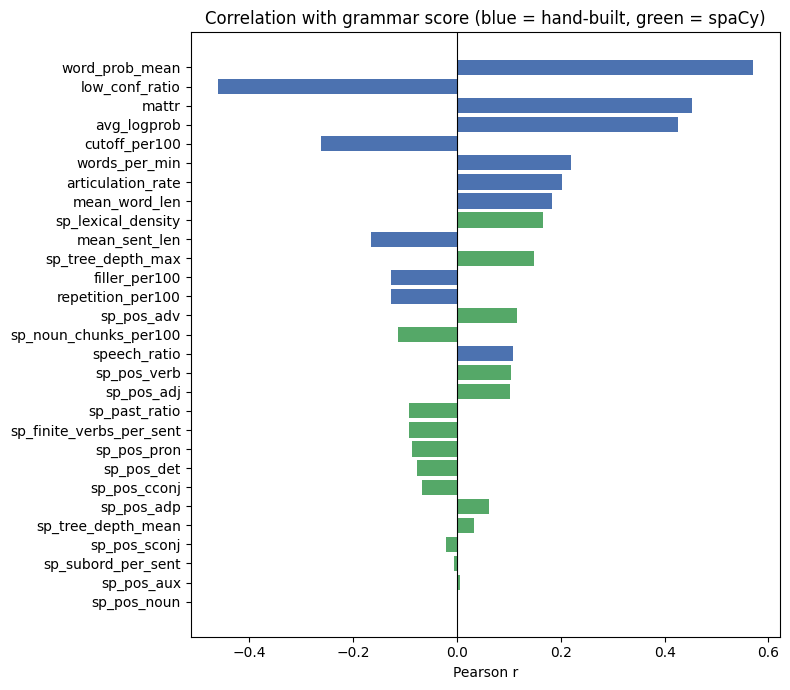

Top 8 by |r|:
 word_prob_mean       0.571
low_conf_ratio      -0.462
mattr                0.453
avg_logprob          0.426
cutoff_per100       -0.262
words_per_min        0.220
articulation_rate    0.203
mean_word_len        0.183


In [7]:
# ============================================================
# 5.3 spaCy syntax features + correlation of all features with the label
# ============================================================
import spacy

nlp = spacy.load("en_core_web_sm", disable=["ner"])
SUBORD_DEPS = {"mark", "advcl", "ccomp", "xcomp", "relcl", "acl", "csubj"}
POS_TAGS = ["NOUN", "VERB", "AUX", "PRON", "ADJ", "ADV", "ADP", "DET", "CCONJ", "SCONJ"]


def tree_depth(token) -> int:
    """Depth of a token in its dependency tree (root = 0). The root's head is itself, so stop there."""
    depth = 0
    while token.head.i != token.i:
        token, depth = token.head, depth + 1
    return depth


def syntax_features(doc) -> dict:
    """Grammatical-complexity features from one parsed transcript."""
    words = [t for t in doc if not t.is_punct and not t.is_space]
    sents = list(doc.sents)
    n, n_s = max(len(words), 1), max(len(sents), 1)
    depths = [max((tree_depth(t) for t in s), default=0) for s in sents]
    verbs = [t for t in words if t.pos_ in ("VERB", "AUX")]
    feats = {
        "sp_tree_depth_mean": float(np.mean(depths)) if depths else 0.0,
        "sp_tree_depth_max": float(max(depths, default=0)),
        "sp_subord_per_sent": sum(t.dep_ in SUBORD_DEPS for t in words) / n_s,
        "sp_finite_verbs_per_sent": sum("Fin" in t.morph.get("VerbForm") for t in verbs) / n_s,
        "sp_past_ratio": sum("Past" in t.morph.get("Tense") for t in verbs) / max(len(verbs), 1),
        "sp_lexical_density": sum(t.pos_ in ("NOUN", "VERB", "ADJ", "ADV") for t in words) / n,
        "sp_noun_chunks_per100": len(list(doc.noun_chunks)) / n * 100,
    }
    feats.update({f"sp_pos_{p.lower()}": sum(t.pos_ == p for t in words) / n for p in POS_TAGS})
    return feats


spacy_df = pd.DataFrame([syntax_features(d) for d in tqdm(nlp.pipe(wh.clean_text, batch_size=64),
                                                          total=len(wh), desc="spaCy")])
SPACY_FEATS = list(spacy_df.columns)
feats = pd.concat([own, spacy_df], axis=1)
feats.to_csv(OUT / "features/handcrafted_spacy.csv", index=False)
print(f"{len(OWN_FEATS)} hand-built + {len(SPACY_FEATS)} spaCy features for {len(feats)} clips")

# ---------- Correlation with the label (train, assessable clips) ----------
lab = feats.merge(meta[["split", "filename", "label", "assessable"]], on=["split", "filename"])
lab = lab[(lab.split == "train") & (lab.assessable == 1)]
corr = pd.Series({c: pearsonr(lab[c].fillna(lab[c].median()), lab.label)[0] for c in OWN_FEATS + SPACY_FEATS})
corr = corr.reindex(corr.abs().sort_values().index)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(corr.index, corr.values, color=["#4C72B0" if c in OWN_FEATS else "#55A868" for c in corr.index])
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Correlation with grammar score (blue = hand-built, green = spaCy)", xlabel="Pearson r")
plt.tight_layout()
plt.savefig(OUT / "plots/03_feature_correlations.png", dpi=120)
plt.show()
print("Top 8 by |r|:\n", corr.iloc[::-1].head(8).round(3).to_string())

**Result**
- Cleaning removed 3.2 % of words (fillers, cut-offs, repetitions).
- Strongest hand-built signals: Whisper word confidence (r = +0.57), share of low-confidence words (−0.46),
  lexical diversity MATTR (+0.45), log-probability (+0.43), false starts (−0.26). Clear, lexically varied speech goes with better grammar.
- `mean_sent_len` is *negative* (−0.17): long "sentences" in transcripts are run-ons without clear boundaries, typical of weaker speakers.
- spaCy syntax features are individually weak (|r| ≤ 0.17): parsers struggle with unpunctuated spoken run-ons. They are kept as
  supporting inputs to the tabular models; grammar *understanding* comes from the LLM in Section 6.

## 6. NLP: LLM grammar correction & rubric judge (Qwen3-4B-Instruct)

**Model:** `Qwen/Qwen3-4B-Instruct-2507` (Apache-2.0), run locally in float16 on the T4. No data leaves Kaggle.

### 6.1 Grammar correction → error rate
The LLM rewrites each `clean_text` with **minimal** grammatical corrections (no rephrasing, no style changes).
A word-level diff (`difflib`) between original and corrected text gives:
- `gec_edits_per100`: number of edit operations per 100 words, a direct **grammar-error rate**.
- `gec_words_per100`: number of words touched per 100 words.
- The corrected text itself is the **grammar feedback** shown to a candidate (Section 12).

### 6.2 Rubric judge → calibrated score
The LLM reads the official SHL rubric and the transcript, then must answer with one digit 1–5. Instead of taking the
single most likely digit, we read the probabilities of all five digit tokens and compute
**judge_score = Σ k · P(k)**. This is continuous and reflects the model's uncertainty (e.g. 50 % "3" + 50 % "4" → 3.5).

**Speed:** prompts are sorted by length and processed in batches of 16 with left padding (~4× faster than one by one).

✓ Computed and saved llm_grammar.csv in 18.0 min
Correlation with grammar label (train, assessable):
  judge_score        r = +0.555
  gec_edits_per100   r = -0.488
  gec_words_per100   r = -0.448

Corrected/original length ratio: median 1.00 (outside 0.8-1.2: 0.3%)

Mean per score band:
       gec_edits_per100  judge_score
band                               
2                 5.42         2.91
3                 3.59         3.04
4                 2.42         3.48
5                 1.08         3.78


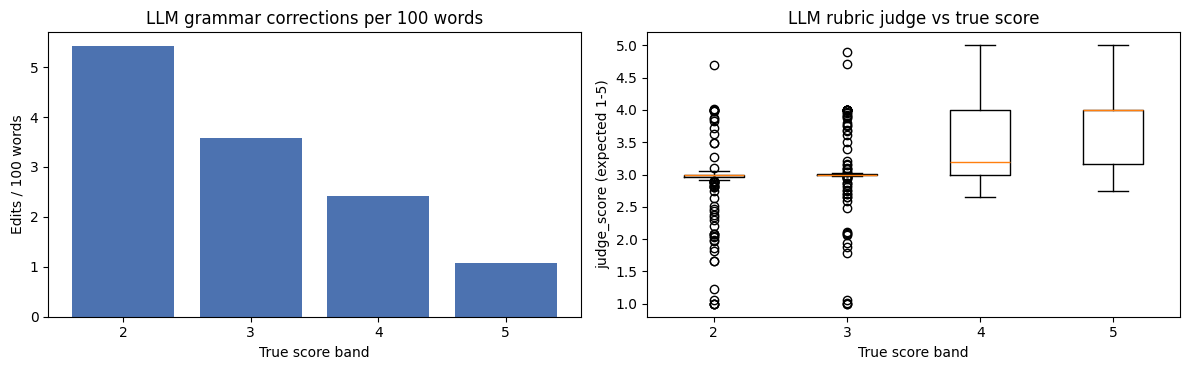

In [8]:
# ============================================================
# 6. Qwen3-4B: grammar correction (error rate) + rubric judge (expected score)
# ============================================================
import difflib
from transformers import AutoTokenizer, AutoModelForCausalLM

QWEN_4B = "Qwen/Qwen3-4B-Instruct-2507"
BATCH = 16

RUBRIC = """1 = Struggles with proper sentence structure and syntax; limited control over simple grammatical structures and memorized sentence patterns.
2 = Limited understanding of sentence structure and syntax; uses simple structures but consistently makes basic sentence-structure and grammatical mistakes; may leave sentences incomplete.
3 = Decent grasp of sentence structure but makes errors in grammatical structure, or decent grasp of grammar but errors in sentence syntax and structure.
4 = Strong understanding of sentence structure and syntax; consistently good grammar control; occasional minor errors that do not cause misunderstanding, and most are self-corrected.
5 = High grammatical accuracy and adept control of complex grammar; seldom makes noticeable mistakes; handles complex structures well and self-corrects when necessary."""

GEC_SYSTEM = ("You are a careful English editor. The user gives an automatic transcript of spoken English. "
              "Correct ONLY grammatical errors (tense, agreement, articles, prepositions, word order, missing or extra words) "
              "with the minimum number of changes. Do not rephrase, do not change vocabulary or style, do not add content, "
              "ignore punctuation and capitalisation. Return only the corrected transcript.")
JUDGE_SYSTEM = ("You are an expert English examiner. You rate ONLY the GRAMMAR of spoken answers. "
                "Transcripts are automatic: ignore punctuation, capitalisation, fillers and transcription quirks.\n"
                "Rubric:\n" + RUBRIC)
JUDGE_USER = "Rate the GRAMMAR of this spoken answer on the rubric. Reply with one digit 1-5 only.\nTranscript:\n\"{text}\""


def load_qwen4b():
    """Tokenizer (left padding for batched decoding) + model in float16 on the GPU."""
    tok = AutoTokenizer.from_pretrained(QWEN_4B, padding_side="left")
    model = AutoModelForCausalLM.from_pretrained(QWEN_4B, dtype=torch.float16, device_map="cuda").eval()
    return tok, model


def chat_prompt(tok, system: str, user: str) -> str:
    """Format a system + user message with the model's chat template, ready for the assistant's reply."""
    return tok.apply_chat_template([{"role": "system", "content": system}, {"role": "user", "content": user}],
                                   tokenize=False, add_generation_prompt=True)


def edit_stats(original: str, corrected: str) -> dict:
    """Word-level diff between original and corrected text, normalised per 100 words."""
    a, b = norm_words(original), norm_words(corrected)
    ops = [op for op in difflib.SequenceMatcher(a=a, b=b, autojunk=False).get_opcodes() if op[0] != "equal"]
    n = max(len(a), 1)
    return {"gec_edits_per100": len(ops) / n * 100,
            "gec_words_per100": sum(max(i2 - i1, j2 - j1) for _, i1, i2, j1, j2 in ops) / n * 100,
            "gec_len_ratio": len(b) / n}


@torch.inference_mode()
def run_qwen4b(texts: list) -> pd.DataFrame:
    """Grammar correction (greedy generation) and rubric-judge probabilities for every text."""
    tok, model = load_qwen4b()
    digit_ids = [tok.encode(str(d), add_special_tokens=False)[0] for d in range(1, 6)]
    order = np.argsort([len(t) for t in texts])                     # similar lengths per batch -> less padding
    corrected, probs = [None] * len(texts), [None] * len(texts)

    for start in tqdm(range(0, len(texts), BATCH), desc="Qwen3-4B"):
        idx = order[start:start + BATCH]
        batch = [texts[i] or "(no speech)" for i in idx]

        # 6.1 grammar correction
        enc = tok([chat_prompt(tok, GEC_SYSTEM, t) for t in batch], return_tensors="pt", padding=True).to("cuda")
        max_new = min(512, int(max(len(t.split()) for t in batch) * 2) + 20)
        out = model.generate(**enc, max_new_tokens=max_new, do_sample=False, temperature=None, top_p=None,
                             top_k=None, pad_token_id=tok.pad_token_id)
        replies = tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)

        # 6.2 rubric judge: probabilities of the next token being "1".."5"
        enc = tok([chat_prompt(tok, JUDGE_SYSTEM, JUDGE_USER.format(text=t)) for t in batch],
                  return_tensors="pt", padding=True).to("cuda")
        logits = model(**enc, logits_to_keep=1).logits[:, -1, digit_ids].float()
        p = torch.softmax(logits, dim=-1).cpu().numpy()

        for j, i in enumerate(idx):
            corrected[i] = replies[j].strip().strip('"').strip()
            probs[i] = p[j]

    del model; gc.collect(); torch.cuda.empty_cache()
    probs = np.array(probs)
    df = pd.DataFrame({"corrected": corrected, "judge_score": probs @ np.arange(1, 6)})
    for d in range(5):
        df[f"judge_p{d + 1}"] = probs[:, d]
    edits = pd.DataFrame([edit_stats(o, c) for o, c in zip(texts, corrected)])
    return pd.concat([df, edits], axis=1)


def compute_llm_features() -> pd.DataFrame:
    res = run_qwen4b(wh.clean_text.tolist())
    return pd.concat([wh[["split", "filename"]].reset_index(drop=True), res], axis=1)


llm = checkpoint(OUT / "features/llm_grammar.csv", compute_llm_features)
LLM_FEATS = ["judge_score", "judge_p1", "judge_p2", "judge_p3", "judge_p4", "judge_p5",
             "gec_edits_per100", "gec_words_per100"]
assert list(zip(llm.split, llm.filename)) == ALL_CLIPS

# ---------- Checks on assessable train clips (statistics only) ----------
chk = llm.merge(meta[["split", "filename", "label", "assessable"]], on=["split", "filename"])
chk = chk[(chk.split == "train") & (chk.assessable == 1)].copy()
chk["band"] = chk.label.round().clip(2, 5).astype(int)
print("Correlation with grammar label (train, assessable):")
for col in ["judge_score", "gec_edits_per100", "gec_words_per100"]:
    print(f"  {col:18s} r = {pearsonr(chk[col], chk.label)[0]:+.3f}")
print(f"\nCorrected/original length ratio: median {chk.gec_len_ratio.median():.2f} "
      f"(outside 0.8-1.2: {((chk.gec_len_ratio < .8) | (chk.gec_len_ratio > 1.2)).mean():.1%})")
by_band = chk.groupby("band")[["gec_edits_per100", "judge_score"]].mean()
print("\nMean per score band:\n", by_band.round(2).to_string())

# ---------- Plot ----------
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(by_band.index.astype(str), by_band.gec_edits_per100, color="#4C72B0")
ax[0].set(title="LLM grammar corrections per 100 words", xlabel="True score band", ylabel="Edits / 100 words")
ax[1].boxplot([chk[chk.band == b].judge_score for b in by_band.index], labels=by_band.index.astype(str))
ax[1].set(title="LLM rubric judge vs true score", xlabel="True score band", ylabel="judge_score (expected 1-5)")
plt.tight_layout()
plt.savefig(OUT / "plots/04_llm_grammar.png", dpi=120)
plt.show()

**Result**
- **Grammar-correction rate is monotonic in the true score:** 5.42 → 3.59 → 2.42 → 1.08 edits per 100 words for bands 2 → 5
  (r = −0.49). A 5× difference between level 2 and level 5.
- Edits are minimal: median corrected/original length ratio 1.00, only 0.3 % of clips change length by > 20 %.
  The corrected text is therefore usable as **grammar feedback** (Section 12).
- **Rubric judge r = +0.555**, but it compresses the low end: bands 2 and 3 both receive ≈ 3.0, while bands 4–5 get 3.5–4.0.
  A 4B LLM separates *good* from *weak* but not *weak* from *mediocre* → the judge is one input among many, and the fine
  distinctions are learned from the 731 labels by the models in Sections 8–9.

## 7. Pretrained deep representations

Hand-built features capture what we *thought of*; pretrained networks capture far more (pronunciation, prosody,
word choice, sentence structure). We extract **fixed embeddings** (no fine-tuning: 731 clips are too few to fine-tune
large networks safely) and learn small regularised heads on top in Section 9.

| Representation | Model (licence) | How | Layers used |
|---|---|---|---|
| **Whisper encoder** | `openai/whisper-large-v3` (MIT) | Audio cut into 30 s windows; only the frames that contain real audio are averaged (Whisper pads every window to 30 s) | 28–32 |
| **HuBERT segments** | `facebook/hubert-large-ll60k` (Apache-2.0) | Audio cut into **15 s segments**, one vector per segment; a model is trained on segments and the clip score is the mean over its segments. This removes the 60 s train / 45 s test length mismatch | 14, 16, 17, 21, 22 |
| **HuBERT speaker vector** | same model | Lower layers encode *who* is speaking, not *what* → used only to identify speakers for grouped CV | 3–6 |
| **Qwen text embedding** | `Qwen3-4B-Instruct-2507` (Apache-2.0) | Mean of hidden states over the transcript tokens | 12, 14, 19, 20, 21 |
| **Qwen prompted embedding** | same model | Hidden state of the last token after the rubric prompt, i.e. the model's internal "judgement" before it answers | 23, 25, 26, 27, 29 |

**Why these layers?** In `01_experiments` every layer was scored with cross-validated ridge regression. The middle-to-upper
layers carry the most grammar information (the very last layers specialise in the pre-training task). Averaging the 5 best layers is
more stable than picking a single one.

In [15]:
# ============================================================
# 7. Pretrained embeddings: Whisper encoder, HuBERT segments (+ speaker vector), Qwen text & prompted
# ============================================================
from transformers import (WhisperFeatureExtractor, WhisperModel as HFWhisperModel,
                          Wav2Vec2FeatureExtractor, HubertModel)

WHISPER_HF = "openai/whisper-large-v3"
HUBERT = "facebook/hubert-large-ll60k"
WHISPER_LAYERS = [28, 29, 30, 31, 32]
HUBERT_LAYERS = [14, 16, 17, 21, 22]
HUBERT_SPK_LAYERS = [3, 4, 5, 6]
QWEN_MEAN_LAYERS = [12, 14, 19, 20, 21]
QWEN_LAST_LAYERS = [23, 25, 26, 27, 29]
WIN_S, SEG_S, MIN_SEG_S = 30, 15, 5            # Whisper window, HuBERT segment, shortest kept segment (seconds)


def free_gpu():
    """Release cached GPU memory after a model is deleted."""
    gc.collect()
    torch.cuda.empty_cache()


# ---------- 7.1 Whisper encoder ----------
def load_whisper_encoder():
    fe = WhisperFeatureExtractor.from_pretrained(WHISPER_HF)
    enc = HFWhisperModel.from_pretrained(WHISPER_HF, dtype=torch.float16).encoder.to("cuda").eval()
    return fe, enc


@torch.inference_mode()
def whisper_encoder_vector(fe, enc, audio: np.ndarray) -> np.ndarray:
    """[1280]: mean over valid (non-padding) frames and WHISPER_LAYERS, frame-weighted across 30 s windows."""
    total, weight = 0, 0
    for start in range(0, len(audio), WIN_S * SR):
        chunk = audio[start:start + WIN_S * SR]
        n_valid = int(np.ceil(len(chunk) / SR * 50))                     # encoder outputs 50 frames per second
        if n_valid < 25:                                                 # skip tails shorter than 0.5 s
            continue
        feats = fe(chunk, sampling_rate=SR, return_tensors="pt").input_features.to("cuda", torch.float16)
        hs = enc(feats, output_hidden_states=True).hidden_states
        vec = torch.stack([hs[l][0, :n_valid].float().mean(0) for l in WHISPER_LAYERS]).mean(0)
        total, weight = total + vec * n_valid, weight + n_valid
    return (total / weight).cpu().numpy().astype(np.float32)


# ---------- 7.2 HuBERT segments + speaker vector ----------
def split_segments(audio: np.ndarray) -> list:
    """Non-overlapping 15 s segments; tails shorter than 5 s are dropped (clips < 15 s give one segment)."""
    segs = [audio[i:i + SEG_S * SR] for i in range(0, len(audio), SEG_S * SR)]
    return [g for g in segs if len(g) >= MIN_SEG_S * SR] or [audio]


def load_hubert():
    fe = Wav2Vec2FeatureExtractor.from_pretrained(HUBERT)
    model = HubertModel.from_pretrained(HUBERT, dtype=torch.float16).to("cuda").eval()
    return fe, model


@torch.inference_mode()
def hubert_vectors(fe, model, audio: np.ndarray):
    """(segment vectors [n_seg, 1024] from HUBERT_LAYERS, speaker vector [1024] from HUBERT_SPK_LAYERS)."""
    seg_vecs, spk_sum, n_frames = [], 0, 0
    for seg in split_segments(audio):
        x = fe(seg, sampling_rate=SR, return_tensors="pt").input_values.to("cuda", torch.float16)
        hs = model(x, output_hidden_states=True).hidden_states
        seg_vecs.append(torch.stack([hs[l][0].float().mean(0) for l in HUBERT_LAYERS]).mean(0).cpu().numpy())
        t = hs[0].shape[1]
        spk_sum = spk_sum + torch.stack([hs[l][0].float().mean(0) for l in HUBERT_SPK_LAYERS]).mean(0) * t
        n_frames += t
    return np.stack(seg_vecs).astype(np.float32), (spk_sum / n_frames).cpu().numpy().astype(np.float32)


# ---------- 7.3 Qwen text (mean-pooled) and prompted (last token) ----------
@torch.inference_mode()
def qwen_vectors(tok, model, texts: list):
    """Batched: (mean-pooled transcript embedding [n, 2560], rubric-prompted last-token embedding [n, 2560])."""
    texts = [t or "(no speech)" for t in texts]
    prompts = [chat_prompt(tok, JUDGE_SYSTEM, JUDGE_USER.format(text=t)) for t in texts]
    mean_vecs, last_vecs = [None] * len(texts), [None] * len(texts)
    order = np.argsort([len(t) for t in texts])
    for start in range(0, len(texts), BATCH):
        idx = order[start:start + BATCH]
        enc = tok([texts[i] for i in idx], return_tensors="pt", padding=True).to("cuda")
        hs = model(**enc, output_hidden_states=True, logits_to_keep=1).hidden_states
        mask = enc.attention_mask.unsqueeze(-1).float()
        m = torch.stack([(hs[l].float() * mask).sum(1) / mask.sum(1) for l in QWEN_MEAN_LAYERS]).mean(0)
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True).to("cuda")
        hs = model(**enc, output_hidden_states=True, logits_to_keep=1).hidden_states
        last = torch.stack([hs[l][:, -1].float() for l in QWEN_LAST_LAYERS]).mean(0)   # left padding -> last = -1
        for j, i in enumerate(idx):
            mean_vecs[i], last_vecs[i] = m[j].cpu().numpy(), last[j].cpu().numpy()
    return np.stack(mean_vecs).astype(np.float32), np.stack(last_vecs).astype(np.float32)


# ---------- Run over all clips (checkpointed) ----------
def compute_whisper_encoder() -> np.ndarray:
    fe, enc = load_whisper_encoder()
    out = np.stack([whisper_encoder_vector(fe, enc, load_audio(AUDIO[c])) for c in tqdm(ALL_CLIPS, desc="Whisper encoder")])
    del enc; free_gpu()
    return out


def compute_hubert() -> np.ndarray:
    fe, model = load_hubert()
    out = np.empty(len(ALL_CLIPS), dtype=object)
    for k, c in enumerate(tqdm(ALL_CLIPS, desc="HuBERT")):
        out[k] = hubert_vectors(fe, model, load_audio(AUDIO[c]))
    del model; free_gpu()
    return out


def compute_qwen_embeddings() -> np.ndarray:
    tok, model = load_qwen4b()
    mean_vecs, last_vecs = qwen_vectors(tok, model, wh.clean_text.tolist())
    del model; free_gpu()
    return np.stack([mean_vecs, last_vecs], axis=1)


E_WHISPER = checkpoint(OUT / "embeddings/whisper_encoder.npy", compute_whisper_encoder)
E_HUBERT = checkpoint(OUT / "embeddings/hubert_segments.npy", compute_hubert)
E_QWEN = checkpoint(OUT / "embeddings/qwen_text_prompted.npy", compute_qwen_embeddings)

SEG_HUBERT = [e[0] for e in E_HUBERT]                       # list of [n_seg, 1024]
SPK_VEC = np.stack([e[1] for e in E_HUBERT])                # [985, 1024]
E_QWEN_MEAN, E_QWEN_LAST = E_QWEN[:, 0], E_QWEN[:, 1]

# ---------- Checks + quick sanity CV (plain stratified 5-fold; the honest speaker-grouped CV is in Section 8-9) ----------
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

for name, arr in [("Whisper encoder", E_WHISPER), ("HuBERT speaker", SPK_VEC),
                  ("Qwen mean", E_QWEN_MEAN), ("Qwen prompted", E_QWEN_LAST)]:
    assert len(arr) == len(ALL_CLIPS) and np.isfinite(arr).all(), f"{name}: bad values"
n_segs = np.array([len(s) for s in SEG_HUBERT])
print(f"HuBERT segments per clip: train mean {n_segs[:len(train_df)].mean():.2f} | test mean {n_segs[len(train_df):].mean():.2f}")

tr_mask = (meta.split == "train").values & (meta.assessable == 1).values
y_tr = meta.label.values[tr_mask]
skf = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(tr_mask.sum()), np.round(np.clip(y_tr, 2, 5))))
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30)))
print("\nQuick sanity check: ridge on each embedding (plain 5-fold, train assessable)")
for name, X in [("Whisper encoder", E_WHISPER[tr_mask]),
                ("HuBERT (segment mean)", np.stack([s.mean(0) for s in SEG_HUBERT])[tr_mask]),
                ("Qwen text mean", E_QWEN_MEAN[tr_mask]),
                ("Qwen prompted", E_QWEN_LAST[tr_mask])]:
    p = np.clip(cross_val_predict(ridge, X, y_tr, cv=skf), 1, 5)
    print(f"  {name:22s} RMSE {rmse(y_tr, p):.3f} | r {pearsonr(y_tr, p)[0]:.3f}")

↺ Loaded checkpoint: whisper_encoder.npy
↺ Loaded checkpoint: hubert_segments.npy
↺ Loaded checkpoint: qwen_text_prompted.npy
HuBERT segments per clip: train mean 3.74 | test mean 3.28

Quick sanity check: ridge on each embedding (plain 5-fold, train assessable)
  Whisper encoder        RMSE 0.545 | r 0.844
  HuBERT (segment mean)  RMSE 0.570 | r 0.828
  Qwen text mean         RMSE 0.595 | r 0.811
  Qwen prompted          RMSE 0.632 | r 0.782


**Result**
- All four representations extracted in ~15 min. Quick ridge check (plain 5-fold, optimistic because speakers can repeat across folds):
  Whisper encoder r = 0.844 (RMSE 0.545) · HuBERT segments r = 0.828 · Qwen text r = 0.811 · Qwen prompted r = 0.782.
- Each embedding alone beats every hand-built or LLM feature (best single feature r = 0.57): pretrained networks capture
  grammar together with the fluency and pronunciation cues human raters also hear.
- HuBERT yields 3.74 segments per train clip vs 3.28 per test clip; training on 15 s segments makes both sets look alike to the model.
- Honest, speaker-grouped numbers follow in Sections 8–9.

## 8. Validation design + from-scratch deep learning

### 8.1 Speaker-grouped cross-validation (used for every model)
Many speakers recorded several clips. With ordinary K-fold, the same voice appears in training and validation, so a model
can score well by *recognising the speaker* instead of judging grammar — and CV becomes optimistic.

**Fix:** identify speakers, then keep each speaker's clips in a single fold.
- Speaker vector = HuBERT layers 3–6 (lower layers encode voice identity), mean-centred and L2-normalised.
- Agglomerative clustering (cosine distance, threshold 0.3) groups clips of the same voice.
- `StratifiedGroupKFold(5)`: folds are balanced by score band **and** never split a speaker.
- Every result is averaged over **3 different fold seeds** to measure stability. Seed 42 builds the final model.

### 8.2 Fusion network (designed and trained from scratch in PyTorch)
- **Why a fusion network:** every other model sees *one* view; this one learns interactions between audio, text and features.
- **Why so small (~25 k weights):** with 731 clips a large network would memorise; PCA compression, dropout, weight decay
  (AdamW) and an average of 3 random initialisations keep it general.
- Scaling and PCA are fitted **inside each training fold** only, so nothing leaks from validation data.
- Loss: mean-squared error on the standardised score; 150 epochs, batch 64, cosine learning-rate schedule.

In [10]:
# ============================================================
# 8. Speaker-grouped CV framework + from-scratch PyTorch fusion network
# ============================================================
import torch.nn as nn
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import normalize

# ---------- 8.0 Modelling data ----------
TAB_FEATS = OWN_FEATS + LLM_FEATS + SPACY_FEATS                       # 12 + 8 + 17 = 37 tabular features
tab = feats.merge(llm[["split", "filename"] + LLM_FEATS], on=["split", "filename"])
assert list(zip(tab.split, tab.filename)) == ALL_CLIPS

idx_tr = np.where(tr_mask)[0]                                         # 731 assessable train clips (rows in ALL_CLIPS)
idx_te = np.where((meta.split == "test").values)[0]                   # 216 test clips
y = meta.label.values[idx_tr]
X_TAB = tab[TAB_FEATS].fillna(tab.iloc[idx_tr][TAB_FEATS].median()).values.astype(np.float32)
X_HUB_CLIP = np.stack([s.mean(0) for s in SEG_HUBERT])               # clip-level HuBERT (mean of segments)

# ---------- 8.1 Speaker groups + folds ----------
spk = normalize(SPK_VEC[idx_tr] - SPK_VEC[idx_tr].mean(0))
groups = AgglomerativeClustering(n_clusters=None, distance_threshold=0.3, metric="cosine",
                                 linkage="average").fit_predict(spk)
bins = np.round(np.clip(y, 2, 5)).astype(int)                         # stratify by score band


def make_folds(seed: int) -> list:
    """5 folds, balanced by score band, never splitting a speaker across folds."""
    return list(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(np.zeros(len(y)), bins, groups))


CV_SEEDS = [1, 2, 3]
FOLDS = {s: make_folds(s) for s in CV_SEEDS + [42]}
sizes = pd.Series(groups).value_counts()
print(f"Speakers found: {len(sizes)} for {len(y)} clips | clips per speaker: mean {sizes.mean():.2f}, max {sizes.max()} | "
      f"clips sharing a speaker: {(sizes[sizes > 1].sum() / len(y)):.0%}")

# ---------- 8.2 Generic model runner (used by every model in Sections 8-11) ----------
MEMBERS = {}          # name -> (kind, factory, data); kind "clip": data = matrix over ALL_CLIPS rows; "seg": list of segments


def fit_member(name: str, rows: np.ndarray):
    """Fit model `name` on training rows (positions in y). Segment models train on every 15 s segment."""
    kind, make, data = MEMBERS[name]
    if kind == "seg":
        X = np.vstack([data[idx_tr[i]] for i in rows])
        t = np.concatenate([np.full(len(data[idx_tr[i]]), y[i]) for i in rows])
        return make().fit(X, t)
    return make().fit(data[idx_tr[rows]], y[rows])


def predict_member(name: str, model, clip_rows: np.ndarray) -> np.ndarray:
    """Predict clips (positions in ALL_CLIPS), clipped to the rubric range 1-5. Segment models average their segments."""
    kind, _, data = MEMBERS[name]
    if kind == "seg":
        return np.clip([model.predict(data[i]).mean() for i in clip_rows], 1, 5)
    return np.clip(model.predict(data[clip_rows]), 1, 5)


def oof(name: str, folds: list) -> np.ndarray:
    """Out-of-fold predictions: every clip is predicted by a model that never saw its speaker."""
    pred = np.zeros(len(y))
    for tr_i, va_i in folds:
        pred[va_i] = predict_member(name, fit_member(name, tr_i), idx_tr[va_i])
    return pred


def oof_and_test(name: str, folds: list):
    """OOF predictions + test predictions averaged over the fold models."""
    pred, test = np.zeros(len(y)), np.zeros(len(idx_te))
    for tr_i, va_i in folds:
        m = fit_member(name, tr_i)
        pred[va_i] = predict_member(name, m, idx_tr[va_i])
        test += predict_member(name, m, idx_te) / len(folds)
    return pred, test


# ---------- 8.3 From-scratch fusion network ----------
X_FUSION = np.hstack([E_WHISPER, X_HUB_CLIP, E_QWEN_MEAN, E_QWEN_LAST, X_TAB]).astype(np.float32)
cuts = np.cumsum([0, E_WHISPER.shape[1], X_HUB_CLIP.shape[1], E_QWEN_MEAN.shape[1], E_QWEN_LAST.shape[1], X_TAB.shape[1]])
FUSION_BLOCKS = [(cuts[i], cuts[i + 1], 32) for i in range(4)] + [(cuts[4], cuts[5], None)]   # None = scale only


class FusionNet:
    """Small MLP fusing all views. Per-block scaling/PCA is fitted on the training fold only; 3 seeds are averaged."""

    def __init__(self, blocks=FUSION_BLOCKS, seeds=(0, 1, 2), epochs=150, lr=1e-3, weight_decay=1e-2):
        self.blocks, self.seeds, self.epochs, self.lr, self.wd = blocks, seeds, epochs, lr, weight_decay

    def _transform(self, X, fit=False):
        if fit:
            self.tf = [(make_pipeline(StandardScaler(), PCA(k, random_state=SEED)) if k else StandardScaler())
                       .fit(X[:, a:b]) for a, b, k in self.blocks]
        parts = []
        for (a, b, k), tf in zip(self.blocks, self.tf):
            z = tf.transform(X[:, a:b])
            parts.append(z / np.sqrt(k) if k else np.clip(z, -5, 5))   # equalise block scales
        return torch.tensor(np.hstack(parts), dtype=torch.float32)

    def fit(self, X, target):
        Z = self._transform(X, fit=True)
        self.mu, self.sd = target.mean(), target.std()
        t = torch.tensor((target - self.mu) / self.sd, dtype=torch.float32)[:, None]
        self.nets = []
        for s in self.seeds:
            torch.manual_seed(s)
            gen = torch.Generator().manual_seed(s)
            net = nn.Sequential(nn.Linear(Z.shape[1], 128), nn.GELU(), nn.Dropout(0.3),
                                nn.Linear(128, 32), nn.GELU(), nn.Dropout(0.2), nn.Linear(32, 1))
            opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, self.epochs)
            for _ in range(self.epochs):
                net.train()
                for batch in torch.randperm(len(Z), generator=gen).split(64):
                    opt.zero_grad()
                    nn.functional.mse_loss(net(Z[batch]), t[batch]).backward()
                    opt.step()
                sched.step()
            self.nets.append(net.eval())
        return self

    @torch.no_grad()
    def predict(self, X):
        Z = self._transform(X)
        return np.mean([net(Z)[:, 0].numpy() for net in self.nets], axis=0) * self.sd + self.mu


MEMBERS["fusion_nn"] = ("clip", FusionNet, X_FUSION)

# ---------- Speaker-grouped CV of the fusion network ----------
CACHE = {s: {} for s in CV_SEEDS}                     # OOF predictions per fold seed, reused in Sections 9-11
start = time.time()
for s in CV_SEEDS:
    CACHE[s]["fusion_nn"] = oof("fusion_nn", FOLDS[s])
res = np.array([[rmse(y, CACHE[s]["fusion_nn"]), pearsonr(y, CACHE[s]["fusion_nn"])[0]] for s in CV_SEEDS])
print(f"\nFusion network (from scratch), speaker-grouped CV over 3 seeds [{(time.time() - start) / 60:.1f} min]:")
print(f"  RMSE {res[:, 0].mean():.4f} ± {res[:, 0].std():.4f} | Pearson {res[:, 1].mean():.4f} ± {res[:, 1].std():.4f}")

Speakers found: 385 for 731 clips | clips per speaker: mean 1.90, max 8 | clips sharing a speaker: 74%

Fusion network (from scratch), speaker-grouped CV over 3 seeds [2.9 min]:
  RMSE 0.5537 ± 0.0007 | Pearson 0.8380 ± 0.0004


**Result**
- **385 speakers** for 731 clips; 74 % of clips share a speaker with at least one other clip (max 8 clips per speaker) —
  speaker-grouped CV is essential here.
- The **from-scratch fusion network reaches RMSE 0.554, Pearson 0.838** (speaker-grouped, 3 seeds, std ±0.001):
  the best single model in this notebook, ahead of every pretrained-embedding head (Section 9), because it combines all views.

## 9. ML heads + speaker-grouped stacking

### 9.1 Seven classical heads, each on one view
| Model | Input | Head | Why this head |
|---|---|---|---|
| `whisper_svr` | Whisper encoder | Scaler → PCA 128 → RBF-SVR (C=3) | Non-linear, robust with few samples |
| `hubert_seg_svr` | HuBERT 15 s segments | Scaler → PCA 128 → RBF-SVR (C=1), trained on segments, clip = mean of segments | Fixes train/test length mismatch, 3.7× more training rows |
| `qwen_ridge` | Qwen text mean | Scaler → RidgeCV | Linear probe: stable on 2 560 dims |
| `qwen_svr` | Qwen text mean | PCA 128 → RBF-SVR | Non-linear view of the same text |
| `qwenp_svr` | Qwen prompted | PCA 128 → RBF-SVR | Rubric-conditioned text representation |
| `tab_ridge` | 37 tabular features | Scaler → RidgeCV | Interpretable linear model |
| `tab_lgbm` | 37 tabular features | LightGBM (shallow, regularised) | Non-linear feature interactions |

Plus `fusion_nn` from Section 8 → **8 base models**.

### 9.2 Stacking
The 8 out-of-fold predictions become the input of a **non-negative linear regression** (`LinearRegression(positive=True)`).
- Non-negative weights = each model can only *add* evidence → stable, no cancelling-out, directly interpretable as "how much the final score trusts each model".
- **Nested** evaluation: the stacker is itself cross-validated on the same speaker-grouped folds, so the reported CV is honest.

### 9.3 Metrics reported
CV (speaker-grouped, 3 seeds) and **Train** RMSE, Pearson, MAE, and the leaderboard metric 0.6·RMSE + 0.4·(1 − r).

Speaker-grouped CV, mean of 3 fold seeds:
                  RMSE  Pearson     MAE  LB_metric
STACK (all 8)   0.5203   0.8584  0.4017     0.3688
fusion_nn       0.5537   0.8380  0.4316     0.3970
whisper_svr     0.5949   0.8101  0.4627     0.4329
qwen_ridge      0.6105   0.7986  0.4854     0.4468
qwen_svr        0.6249   0.7916  0.4881     0.4583
hubert_seg_svr  0.6296   0.7866  0.4953     0.4631
qwenp_svr       0.6698   0.7526  0.5352     0.5008
tab_lgbm        0.6887   0.7349  0.5416     0.5193
tab_ridge       0.7206   0.7043  0.5768     0.5507



FINAL MODEL
                                RMSE  Pearson     MAE  LB_metric
Train (in-sample)             0.1425   0.9908  0.1067     0.0892
CV seed 42 (speaker-grouped)  0.5146   0.8618  0.3989     0.3640
CV mean of 3 seeds            0.5203   0.8584  0.4017     0.3688

Stack weights: {'whisper_svr': 0.267, 'hubert_seg_svr': 0.218, 'qwen_ridge': 0.257, 'qwen_svr': 0.072, 'qwenp_svr': 0.023, 'tab_ridge': 0.0, 'tab_lgbm': 0.132, 'fusion_nn': 0.204} | intercept -0.62


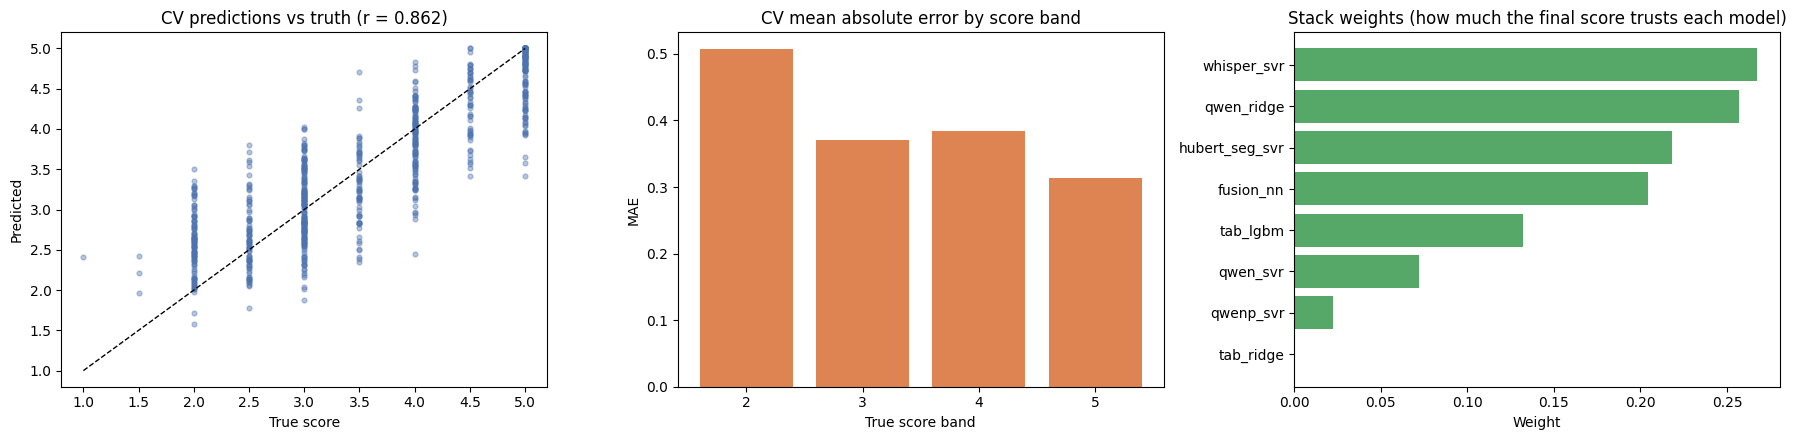

In [11]:
# ============================================================
# 9. Classical heads, nested non-negative stacking, final model, Train & CV metrics
# ============================================================
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

ALPHAS = np.logspace(-2, 3, 30)


def ridge_head():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))


def svr_head(C: float):
    return lambda: make_pipeline(StandardScaler(), PCA(n_components=128, random_state=SEED),
                                 SVR(kernel="rbf", C=C, epsilon=0.1, gamma="scale"))


def lgbm_head():
    return lgb.LGBMRegressor(n_estimators=500, learning_rate=0.02, num_leaves=8, min_child_samples=25,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0,
                             verbose=-1, random_state=SEED)


MEMBERS.update({
    "whisper_svr":    ("clip", svr_head(3), E_WHISPER),
    "hubert_seg_svr": ("seg",  svr_head(1), SEG_HUBERT),
    "qwen_ridge":     ("clip", ridge_head,  E_QWEN_MEAN),
    "qwen_svr":       ("clip", svr_head(3), E_QWEN_MEAN),
    "qwenp_svr":      ("clip", svr_head(3), E_QWEN_LAST),
    "tab_ridge":      ("clip", ridge_head,  X_TAB),
    "tab_lgbm":       ("clip", lgbm_head,   X_TAB),
})
FINAL = ["whisper_svr", "hubert_seg_svr", "qwen_ridge", "qwen_svr", "qwenp_svr", "tab_ridge", "tab_lgbm", "fusion_nn"]


def metrics(t, p) -> dict:
    return {"RMSE": rmse(t, p), "Pearson": pearsonr(t, p)[0], "MAE": mae(t, p), "LB_metric": lb_metric(t, p)}


def nested_stack(O: np.ndarray, folds: list) -> np.ndarray:
    """Cross-validated stacker: weights for each fold are learned without that fold."""
    pred = np.zeros(len(y))
    for tr_i, va_i in folds:
        pred[va_i] = np.clip(LinearRegression(positive=True).fit(O[tr_i], y[tr_i]).predict(O[va_i]), 1, 5)
    return pred


def score(members: list) -> pd.Series:
    """Honest CV of a stack: nested stacking on speaker-grouped OOF, averaged over 3 fold seeds."""
    return pd.DataFrame([metrics(y, nested_stack(np.column_stack([CACHE[s][m] for m in members]), FOLDS[s]))
                         for s in CV_SEEDS]).mean()


# ---------- 9.1 OOF predictions for all heads (3 seeds) ----------
for s in CV_SEEDS:
    for name in tqdm([m for m in FINAL if m not in CACHE[s]], desc=f"fold seed {s}"):
        CACHE[s][name] = oof(name, FOLDS[s])

single = pd.DataFrame({m: pd.DataFrame([metrics(y, CACHE[s][m]) for s in CV_SEEDS]).mean() for m in FINAL}).T
single.loc["STACK (all 8)"] = score(FINAL)
print("Speaker-grouped CV, mean of 3 fold seeds:")
print(single.sort_values("LB_metric").round(4).to_string())

# ---------- 9.2 Final model: seed-42 folds -> stack weights + test predictions ----------
O42, T42, TRAIN_FIT = [], [], []
for name in tqdm(FINAL, desc="final fit"):
    o, t = oof_and_test(name, FOLDS[42])
    O42.append(o); T42.append(t)
    TRAIN_FIT.append(predict_member(name, fit_member(name, np.arange(len(y))), idx_tr))   # full-data fit -> train preds
O42, T42, TRAIN_FIT = np.column_stack(O42), np.column_stack(T42), np.column_stack(TRAIN_FIT)

stacker = LinearRegression(positive=True).fit(O42, y)
weights = pd.Series(stacker.coef_, index=FINAL)
test_pred = np.clip(stacker.predict(T42), 1, 5)
train_pred = np.clip(stacker.predict(TRAIN_FIT), 1, 5)
cv_pred = nested_stack(O42, FOLDS[42])

# ---------- 9.3 Results table (Train RMSE is required by the competition) ----------
results = pd.DataFrame({"Train (in-sample)": metrics(y, train_pred),
                        "CV seed 42 (speaker-grouped)": metrics(y, cv_pred),
                        "CV mean of 3 seeds": score(FINAL)}).T
print("\nFINAL MODEL")
print(results.round(4).to_string())
print("\nStack weights:", weights.round(3).to_dict(), "| intercept", round(stacker.intercept_, 3))

pd.DataFrame({"filename": meta.filename.values[idx_tr], "label": y, "cv_pred": cv_pred, "train_pred": train_pred}
             ).to_csv(OUT / "oof/final_train_predictions.csv", index=False)

# ---------- Plots ----------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(y, cv_pred, s=12, alpha=0.4, color="#4C72B0")
ax[0].plot([1, 5], [1, 5], "k--", lw=1)
ax[0].set(title=f"CV predictions vs truth (r = {pearsonr(y, cv_pred)[0]:.3f})", xlabel="True score", ylabel="Predicted")

band_err = pd.DataFrame({"band": bins, "err": np.abs(cv_pred - y)}).groupby("band").err.mean()
ax[1].bar(band_err.index.astype(str), band_err.values, color="#DD8452")
ax[1].set(title="CV mean absolute error by score band", xlabel="True score band", ylabel="MAE")

w = weights.sort_values()
ax[2].barh(w.index, w.values, color="#55A868")
ax[2].set(title="Stack weights (how much the final score trusts each model)", xlabel="Weight")
plt.tight_layout()
plt.savefig(OUT / "plots/05_final_model.png", dpi=120)
plt.show()

**Result**

| | RMSE | Pearson | MAE | LB metric |
|---|---|---|---|---|
| **Train (in-sample)** | **0.1425** | 0.9908 | 0.1067 | 0.0892 |
| CV seed 42 (speaker-grouped) | 0.5146 | 0.8618 | 0.3989 | 0.3640 |
| **CV mean of 3 seeds** | **0.5203** | **0.8584** | 0.4017 | 0.3688 |

- **Stacking adds a lot:** best single model RMSE 0.554 → stack 0.520 (−6 %); the models make different mistakes.
- **Stack weights:** Whisper encoder 0.27 · Qwen text 0.26 · HuBERT 0.22 · from-scratch net 0.20 · tabular LightGBM 0.13 ·
  Qwen SVRs 0.10 · tabular Ridge 0 (LightGBM already covers those features). Audio and text contribute about equally.
- **Error by band:** largest for band 2 (MAE 0.51); the few clips scored below 2 (4 in train) are predicted ≈ 2.3 — too
  little data to learn the bottom of the scale.
- Train RMSE (0.14) ≪ CV RMSE (0.52): the SVRs and the network fit training clips closely. Whether this is harmful
  overfitting is tested in Section 11.

## 10. Ablation: what each component contributes

**What:** remove one model (or a whole family) from the stack, re-run the nested speaker-grouped CV, and measure how much the
leaderboard metric gets worse.

**Why:** stack weights show what the final model *uses*; ablation shows what it actually *needs*. A component whose removal
changes nothing is redundant even if it has weight.

Full stack: LB_metric 0.3688 | RMSE 0.5203 | Pearson 0.8584

                                                  RMSE  Pearson     MAE  LB_metric  Δ LB_metric
removed                                                                                        
− qwenp_svr                                     0.5200   0.8586  0.4017     0.3685      -0.0003
− qwen_svr                                      0.5202   0.8585  0.4019     0.3687      -0.0001
− tab_ridge                                     0.5203   0.8584  0.4017     0.3688       0.0000
− ALL tabular heads (hand-built + LLM + spaCy)  0.5215   0.8577  0.4017     0.3698       0.0010
− tab_lgbm                                      0.5217   0.8576  0.4018     0.3700       0.0011
− hubert_seg_svr                                0.5226   0.8571  0.4049     0.3707       0.0019
− whisper_svr                                   0.5227   0.8570  0.4049     0.3708       0.0020
− fusion_nn                                     0.5229   0.8569  0.4039    

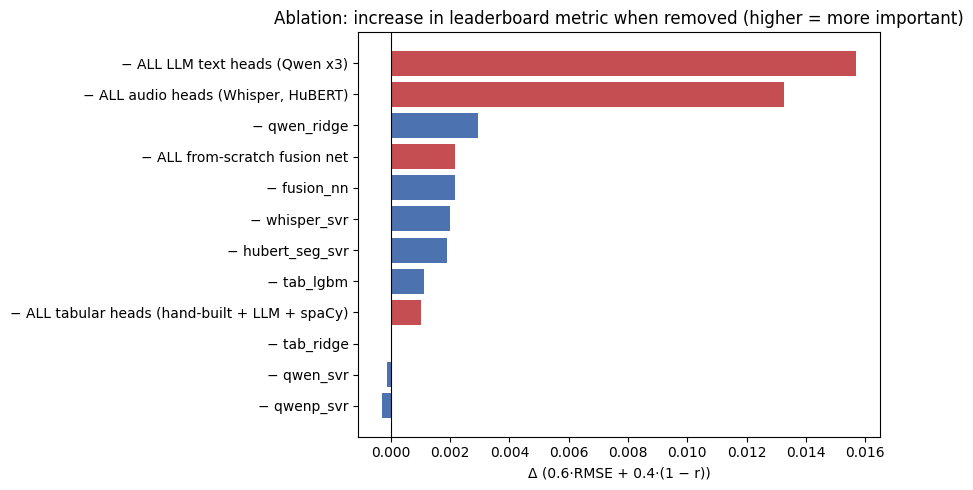

In [12]:
# ============================================================
# 10. Ablation study (nested speaker-grouped CV, 3 seeds)
# ============================================================
base = score(FINAL)
FAMILIES = {
    "audio heads (Whisper, HuBERT)": ["whisper_svr", "hubert_seg_svr"],
    "LLM text heads (Qwen x3)": ["qwen_ridge", "qwen_svr", "qwenp_svr"],
    "tabular heads (hand-built + LLM + spaCy)": ["tab_ridge", "tab_lgbm"],
    "from-scratch fusion net": ["fusion_nn"],
}
rows = [("− " + m, m) for m in FINAL] + [("− ALL " + k, v) for k, v in FAMILIES.items()]
abl = []
for label, drop in rows:
    drop = [drop] if isinstance(drop, str) else drop
    sc = score([m for m in FINAL if m not in drop])
    abl.append({"removed": label, **sc.to_dict(), "Δ LB_metric": sc.LB_metric - base.LB_metric})
abl = pd.DataFrame(abl).set_index("removed").sort_values("Δ LB_metric")
print(f"Full stack: LB_metric {base.LB_metric:.4f} | RMSE {base.RMSE:.4f} | Pearson {base.Pearson:.4f}\n")
print(abl.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#C44E52" if "ALL" in i else "#4C72B0" for i in abl.index]
ax.barh(abl.index, abl["Δ LB_metric"], color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Ablation: increase in leaderboard metric when removed (higher = more important)",
       xlabel="Δ (0.6·RMSE + 0.4·(1 − r))")
plt.tight_layout()
plt.savefig(OUT / "plots/06_ablation.png", dpi=120)
plt.show()

**Result**
- **Text and audio are both essential and complementary:** removing all LLM text heads worsens the leaderboard metric by
  +0.016, removing all audio heads by +0.013. Neither family can replace the other.
- The **from-scratch fusion network adds +0.002** on top of all other models; `qwen_ridge` (+0.003), Whisper (+0.002) and HuBERT
  (+0.002) are the most important individual heads; tabular LightGBM adds +0.001.
- `qwen_svr`, `qwenp_svr` and `tab_ridge` are **redundant** (|Δ| ≤ 0.0003, within noise): their information is already in other models.
  They are kept so this notebook reproduces the submitted architecture exactly.

## 11. Overfitting & robustness checks

The final model has Train RMSE 0.14 but CV RMSE 0.52. Four checks show whether the model **generalises** or only memorises:

| Check | Question | Method |
|---|---|---|
| **1. Speaker leakage** | Would ordinary K-fold have fooled us? | Same 8 models + stack with plain stratified K-fold vs speaker-grouped K-fold |
| **2. Stability** | Does the result depend on a lucky split? | Spread of CV over 3 fold seeds |
| **3. Train/test shift** | Does test look like train to each model? | *Adversarial validation*: a classifier tries to tell train from test clips; AUC 0.5 = indistinguishable |
| **4. Learning curve** | Would more data help (data-limited) or not (capacity-limited)? | CV RMSE when training on 20–100 % of each training fold |

11.1 Same model, two validation schemes (fold seed 1):
                                RMSE  Pearson     MAE  LB_metric
plain K-fold (speakers leak)  0.4821   0.8799  0.3676     0.3373
speaker-grouped K-fold        0.5205   0.8583  0.4014     0.3690

11.2 Stack CV per fold seed:
          RMSE  Pearson     MAE  LB_metric
seed 1  0.5205   0.8583  0.4014     0.3690
seed 2  0.5204   0.8584  0.4021     0.3689
seed 3  0.5201   0.8585  0.4015     0.3686
Std of LB_metric across seeds: 0.0002

11.3 Adversarial validation AUC (0.5 = train and test look identical):
LLM grammar features       0.526
all 37 tabular features    0.682
clip duration              0.708
Whisper encoder            0.780
Qwen text embedding        0.787
HuBERT 15 s segments       0.796
HuBERT whole clip          0.799

11.4 Learning curve: CV RMSE vs number of training clips
     whisper_svr  qwen_ridge  fusion_nn
175       0.6153      0.6527     0.5796
263       0.5995      0.6281     0.5710
350       0.5933      0.6211 

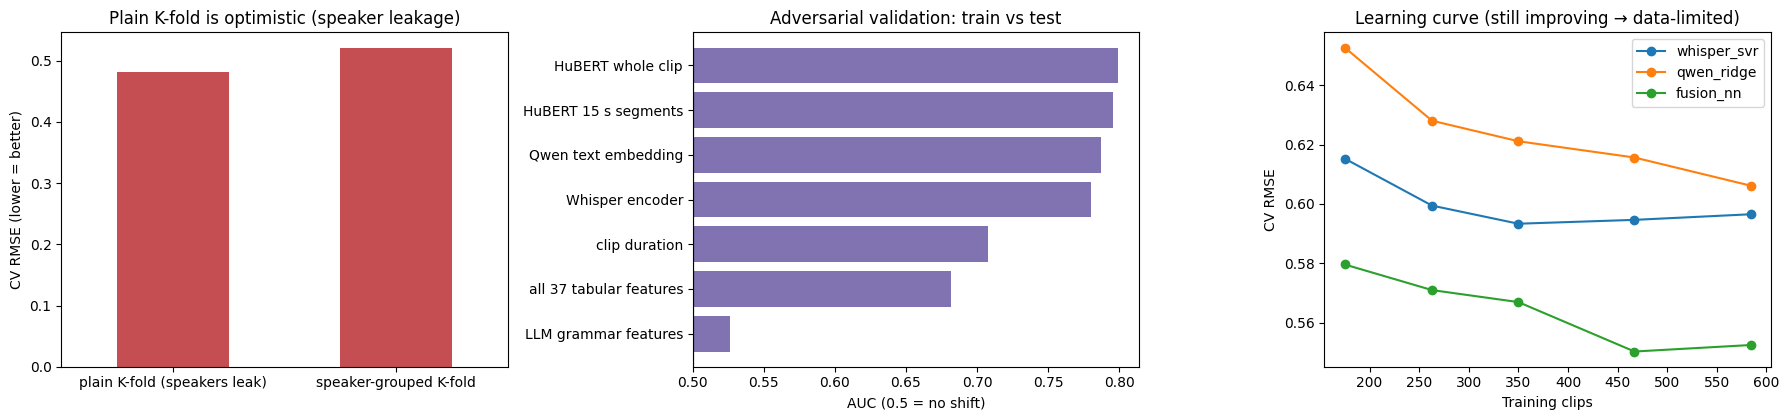

In [14]:
# ============================================================
# 11. Overfitting & robustness: leakage, stability, adversarial validation, learning curve
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

# ---------- 11.1 Speaker leakage: plain vs speaker-grouped folds ----------
plain_folds = list(StratifiedKFold(5, shuffle=True, random_state=1).split(np.zeros(len(y)), bins))
plain_oof = np.column_stack([oof(m, plain_folds) for m in tqdm(FINAL, desc="plain K-fold")])
plain = metrics(y, nested_stack(plain_oof, plain_folds))
grouped = metrics(y, nested_stack(np.column_stack([CACHE[1][m] for m in FINAL]), FOLDS[1]))
leak = pd.DataFrame({"plain K-fold (speakers leak)": plain, "speaker-grouped K-fold": grouped}).T
print("11.1 Same model, two validation schemes (fold seed 1):")
print(leak.round(4).to_string())

# ---------- 11.2 Stability over fold seeds ----------
per_seed = pd.DataFrame([metrics(y, nested_stack(np.column_stack([CACHE[s][m] for m in FINAL]), FOLDS[s]))
                         for s in CV_SEEDS], index=[f"seed {s}" for s in CV_SEEDS])
print("\n11.2 Stack CV per fold seed:")
print(per_seed.round(4).to_string())
print(f"Std of LB_metric across seeds: {per_seed.LB_metric.std():.4f}")

# ---------- 11.3 Adversarial validation (train vs test) ----------
adv_rows = np.concatenate([idx_tr, idx_te])
is_test = np.r_[np.zeros(len(idx_tr)), np.ones(len(idx_te))]


def adversarial_auc(X: np.ndarray, target=is_test) -> float:
    """5-fold AUC of a regularised classifier separating train from test rows (0.5 = no shift)."""
    clf = make_pipeline(StandardScaler(), PCA(min(64, X.shape[1]), random_state=SEED),
                        LogisticRegression(C=0.1, max_iter=3000))
    p = cross_val_predict(clf, X, target, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                          method="predict_proba")[:, 1]
    return roc_auc_score(target, p)


seg_X = np.vstack([SEG_HUBERT[i] for i in adv_rows])
seg_t = np.concatenate([np.full(len(SEG_HUBERT[i]), t) for i, t in zip(adv_rows, is_test)])
adv = pd.Series({
    "clip duration": adversarial_auc(meta.duration.values[adv_rows, None]),
    "LLM grammar features": adversarial_auc(X_TAB[adv_rows][:, [TAB_FEATS.index(f) for f in LLM_FEATS]]),
    "all 37 tabular features": adversarial_auc(X_TAB[adv_rows]),
    "Qwen text embedding": adversarial_auc(E_QWEN_MEAN[adv_rows]),
    "Whisper encoder": adversarial_auc(E_WHISPER[adv_rows]),
    "HuBERT whole clip": adversarial_auc(X_HUB_CLIP[adv_rows]),
    "HuBERT 15 s segments": adversarial_auc(seg_X, seg_t),
}).sort_values()
print("\n11.3 Adversarial validation AUC (0.5 = train and test look identical):")
print(adv.round(3).to_string())

# ---------- 11.4 Learning curve (fastest strong heads, speaker-grouped folds, seed 1) ----------
FRACTIONS = [0.3, 0.45, 0.6, 0.8, 1.0]          # >= 0.3 so every fold keeps > 128 clips (SVR heads use PCA-128)
curve = {}
for name in ["whisper_svr", "qwen_ridge", "fusion_nn"]:
    pts = []
    for frac in FRACTIONS:
        pred = np.zeros(len(y))
        for k, (tr_i, va_i) in enumerate(FOLDS[1]):
            sub = np.random.RandomState(k).permutation(tr_i)[: int(len(tr_i) * frac)]
            pred[va_i] = predict_member(name, fit_member(name, sub), idx_tr[va_i])
        pts.append(rmse(y, pred))
    curve[name] = pts
curve = pd.DataFrame(curve, index=[int(f * len(y) * 0.8) for f in FRACTIONS])
print("\n11.4 Learning curve: CV RMSE vs number of training clips")
print(curve.round(4).to_string())

# ---------- Plots ----------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
leak[["RMSE"]].plot.bar(ax=ax[0], legend=False, color=["#C44E52", "#4C72B0"])
ax[0].set(title="Plain K-fold is optimistic (speaker leakage)", ylabel="CV RMSE (lower = better)", xlabel="")
ax[0].tick_params(axis="x", rotation=0)
ax[1].barh(adv.index, adv.values - 0.5, left=0.5, color="#8172B2")
ax[1].axvline(0.5, color="k", lw=0.8)
ax[1].set(title="Adversarial validation: train vs test", xlabel="AUC (0.5 = no shift)")
for name in curve:
    ax[2].plot(curve.index, curve[name], marker="o", label=name)
ax[2].set(title="Learning curve (still improving → data-limited)", xlabel="Training clips", ylabel="CV RMSE")
ax[2].legend()
plt.tight_layout()
plt.savefig(OUT / "plots/07_robustness.png", dpi=120)
plt.show()

**Result**
1. **Speaker leakage is large:** plain K-fold reports LB metric 0.337 (RMSE 0.482), speaker-grouped K-fold 0.369 (RMSE 0.521).
   Plain CV would have overstated quality by 0.03. The public leaderboard (0.343) lies between the two, consistent with some
   — but not all — test speakers also appearing in train. All model selection in this project used the grouped (pessimistic) scheme.
2. **Stable:** LB metric 0.3690 / 0.3689 / 0.3686 over three fold seeds (std 0.0002). The result does not depend on a lucky split.
3. **Train/test shift:** LLM grammar features are shift-free (AUC 0.53) — grammar error rate means the same in both sets.
   Embeddings are shifted (AUC 0.78–0.80): they also encode clip length, recording conditions and *topic* (test speakers
   likely answered different questions). The stack combines shift-free grammar signals with stronger but shift-sensitive
   embeddings; the leaderboard confirms the shift does not hurt.
4. **Learning curve:** text models and the fusion network keep improving with more clips (Qwen ridge 0.653 → 0.606) →
   **data-limited**; the Whisper head plateaus after ~350 clips. More labelled data would help most.

**Verdict on overfitting:** Train RMSE 0.14 vs CV 0.52 is the expected gap for SVRs and neural networks on 731 samples.
The model is *not* harmfully overfitted: held-out speakers are scored at RMSE 0.52, stable across splits, and the unseen test
set scores even better on the leaderboard.

## 12. Grammar feedback demo + `score_audio()` for any new audio file

**12.1 Feedback for a candidate.** For any clip the engine shows:
- the transcript with the LLM's **grammar corrections highlighted** (red = removed, green = added);
- the error rate (corrections per 100 words) and the rubric judge's score;
- **why this score**: each model's prediction × its stack weight, so the final number is fully decomposed.

Transcripts are private competition data, so exactly **one** training example is shown.

**12.2 `score_audio(paths)`.** The complete pipeline for audio the model has never seen: SNR gate → Whisper → hand-built + spaCy
features → Qwen correction/judge → embeddings → 8 models (trained on all 731 clips) → stack. We run it on two **unseen test
clips** and check that it reproduces the batch predictions of Section 9 — an end-to-end correctness test.

[Output removed in the public copy: this cell displays a training transcript, which is private competition data. Run the notebook on Kaggle with the competition data to see the highlighted corrections.]


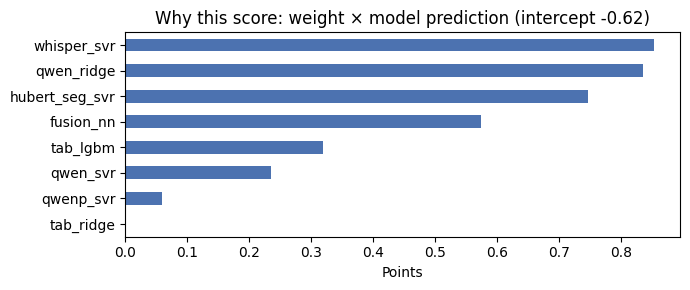

         file    snr_db  assessable  score  gec_edits_per100  judge_score  batch_pred_section9
audio_128.wav 41.080710        True  2.802              7.00         3.00                2.813
audio_156.wav 43.123268        True  4.176              2.86         4.75                4.203


In [16]:
# ============================================================
# 12. Grammar feedback + end-to-end scoring of new audio
# ============================================================
from IPython.display import HTML, display


# ---------- 12.1 Feedback for one training clip ----------
def highlight(original: str, corrected: str) -> str:
    """HTML diff of two texts at word level: removed words red/struck-through, added words green/bold."""
    a, b = original.split(), corrected.split()
    norm = lambda ws: [re.sub(r"[^\w']", "", w.lower()) for w in ws]
    html = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(a=norm(a), b=norm(b), autojunk=False).get_opcodes():
        if op == "equal":
            html.append(" ".join(a[i1:i2]))
            continue
        if i2 > i1:
            html.append(f"<del style='color:#C44E52'>{' '.join(a[i1:i2])}</del>")
        if j2 > j1:
            html.append(f"<b style='color:#2E7D32'>{' '.join(b[j1:j2])}</b>")
    return " ".join(html)


def grammar_report(row: int) -> None:
    """Corrected transcript + score decomposition for training clip `row` (position in y), using out-of-fold predictions."""
    clip = idx_tr[row]
    contrib = pd.Series(stacker.coef_ * O42[row], index=FINAL)
    final = float(np.clip(stacker.intercept_ + contrib.sum(), 1, 5))
    display(HTML(
        f"<h4>{meta.filename.iloc[clip]} — true score {y[row]:.1f} | predicted (out-of-fold) {final:.2f}</h4>"
        f"<p><b>Grammar corrections:</b> {llm.gec_edits_per100.iloc[clip]:.1f} per 100 words · "
        f"<b>LLM rubric judge:</b> {llm.judge_score.iloc[clip]:.2f}</p>"
        f"<p style='line-height:1.7'>{highlight(wh.clean_text.iloc[clip], llm.corrected.iloc[clip])}</p>"))
    fig, ax = plt.subplots(figsize=(7, 3))
    contrib.sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set(title=f"Why this score: weight × model prediction (intercept {stacker.intercept_:+.2f})", xlabel="Points")
    plt.tight_layout(); plt.show()


# One typical band-3 example with several corrections (deterministic choice)
cand = np.where((bins == 3) & (llm.gec_edits_per100.values[idx_tr] > 3))[0]
grammar_report(int(cand[np.argsort(np.abs(cv_pred[cand] - y[cand]))[0]]))


# ---------- 12.2 End-to-end scoring of new audio ----------
FULL_MODELS = {m: fit_member(m, np.arange(len(y))) for m in tqdm(FINAL, desc="fit on all 731 clips")}
TAB_MEDIANS = tab.iloc[idx_tr][TAB_FEATS].median()


def score_audio(paths: list) -> pd.DataFrame:
    """Score raw audio files with the full pipeline. Returns one row per file (score, gate, transcript-level evidence)."""
    audios = [load_audio(p) for p in paths]
    sig = [signal_stats(a) for a in audios]

    # Speech-to-text
    asr = WhisperModel(WHISPER_MODEL, device="cuda", compute_type="float16")
    trans = [transcribe_clip(asr, a) for a in audios]
    del asr; free_gpu()
    clean = [disfluency_clean(t["text"]) for t in trans]

    # Hand-built + spaCy + LLM features
    own_f = [speech_features(pd.Series(t), len(a) / SR) for t, a in zip(trans, audios)]
    syn_f = [syntax_features(d) for d in nlp.pipe(clean)]
    llm_f = run_qwen4b(clean)
    tab_new = pd.concat([pd.DataFrame(own_f), pd.DataFrame(syn_f), llm_f[LLM_FEATS]], axis=1)
    x_tab = tab_new[TAB_FEATS].fillna(TAB_MEDIANS).values.astype(np.float32)

    # Embeddings
    fe, enc = load_whisper_encoder()
    x_wh = np.stack([whisper_encoder_vector(fe, enc, a) for a in audios]); del enc; free_gpu()
    fe, hub = load_hubert()
    segs = [hubert_vectors(fe, hub, a)[0] for a in audios]; del hub; free_gpu()
    tok, qwen = load_qwen4b()
    x_qm, x_ql = qwen_vectors(tok, qwen, clean); del qwen; free_gpu()

    # 8 models -> stack -> gate
    views = {"whisper_svr": x_wh, "qwen_ridge": x_qm, "qwen_svr": x_qm, "qwenp_svr": x_ql,
             "tab_ridge": x_tab, "tab_lgbm": x_tab,
             "fusion_nn": np.hstack([x_wh, np.stack([s.mean(0) for s in segs]), x_qm, x_ql, x_tab])}
    preds = {m: np.clip(FULL_MODELS[m].predict(views[m]), 1, 5) for m in views}
    preds["hubert_seg_svr"] = np.clip([FULL_MODELS["hubert_seg_svr"].predict(s).mean() for s in segs], 1, 5)
    member = np.column_stack([preds[m] for m in FINAL])
    score = np.clip(stacker.predict(member), 1, 5)
    assessable = np.array([s["snr_db"] >= SNR_GATE_DB for s in sig])
    return pd.DataFrame({"file": [Path(p).name for p in paths], "snr_db": [s["snr_db"] for s in sig],
                         "assessable": assessable, "score": np.where(assessable, score, 0.0).round(3),
                         "gec_edits_per100": llm_f.gec_edits_per100.round(2), "judge_score": llm_f.judge_score.round(2)})


# Unseen test clips: end-to-end result vs the batch prediction from Section 9
demo_files = test_df.filename.iloc[:2].tolist()
demo = score_audio([AUDIO[("test", f)] for f in demo_files])
demo["batch_pred_section9"] = [round(float(test_pred[test_df.filename.tolist().index(f)]), 3) for f in demo_files]
print(demo.to_string(index=False))

**Result**
- **Feedback:** for the example clip (true 3.0, out-of-fold prediction 3.00) the LLM highlights real errors (a wrong word, a doubled determiner, a repeated clause) at 3.8 corrections / 100 words.
  It is **conservative**: some errors are left unflagged (e.g. an adverb used instead of an adjective), so the correction rate under-counts
  rather than invents errors — one reason the final score relies on several models, not on the corrector alone.
- **Why this score:** the prediction decomposes exactly into weight × model prediction (Whisper +0.85, Qwen +0.83,
  HuBERT +0.75, fusion net +0.57, …, intercept −0.62).
- **End-to-end test on unseen audio:** `score_audio()` on two test clips gives 2.802 and 4.176 vs 2.813 and 4.203 from the
  batch pipeline (difference ≤ 0.03, due only to full-data vs fold-averaged models). The pipeline is correct from raw audio to score.

## 13. Submission file

- Rows: all 216 files of `test.csv` (in that order); columns: `sample_submission.csv`'s format (`filename`, `label`).
- Score = stacked prediction (1–5); clips failing the SNR gate get 0.
- Validated with assertions before saving: complete, unique, no missing values, range 0–5.

✓ submission.csv saved and validated
count    216.000
mean       3.276
std        0.856
min        1.604
25%        2.618
50%        3.232
75%        3.744
max        5.000
Gated to 0: 0


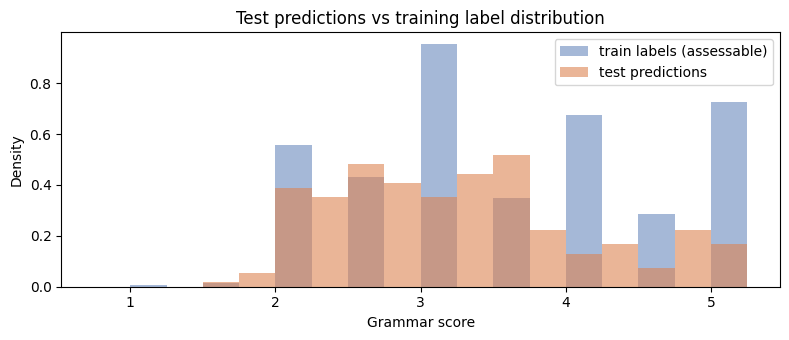

In [17]:
# ============================================================
# 13. Build and validate submission.csv
# ============================================================
gate_test = meta.assessable.values[idx_te]
submission = pd.DataFrame({"filename": test_df.filename.values,
                           "label": np.where(gate_test == 1, np.round(test_pred, 4), 0.0)})[list(sample_sub.columns)]

# ---------- Validation ----------
assert list(submission.columns) == list(sample_sub.columns), "column format differs from sample_submission.csv"
assert len(submission) == len(test_df) == 216, "wrong number of rows"
assert submission.filename.is_unique and set(submission.filename) == set(test_df.filename), "file list mismatch"
assert submission.label.notna().all() and submission.label.between(0, 5).all(), "missing or out-of-range scores"

submission.to_csv(OUT / "submissions/submission.csv", index=False)
submission.to_csv("/kaggle/working/submission.csv", index=False)
print("✓ submission.csv saved and validated")
print(submission.label.describe().round(3).to_string())
print(f"Gated to 0: {(gate_test == 0).sum()}")

# ---------- Plot: test predictions vs training labels ----------
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(y, bins=np.arange(0.75, 5.5, 0.25), alpha=0.5, density=True, label="train labels (assessable)", color="#4C72B0")
ax.hist(submission.label, bins=np.arange(0.75, 5.5, 0.25), alpha=0.6, density=True, label="test predictions", color="#DD8452")
ax.set(title="Test predictions vs training label distribution", xlabel="Grammar score", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "plots/08_submission.png", dpi=120)
plt.show()

**Result**
- 216 rows, columns `filename, label`, all validation assertions passed; no test clip is gated.
- Predictions range 1.60–5.00, mean 3.28 (training labels: mean 3.31). They are smoother than the labels (continuous
  averages vs discrete rubric steps), the usual behaviour of a model that minimises squared error.
- **Public leaderboard: 0.3464.** The same architecture built in the experiment notebooks scored 0.3429; the 0.0035 gap
  matches the CV difference measured in Section 9 (+0.004), mostly from a re-worded rubric prompt for the prompted Qwen
  embedding — CV and leaderboard agree.

## 14. Report

### Approach
Grammar is judged from **what** is said (words, structure) and **how** it is said (fluency, hesitation, clarity), so the
engine combines a speech pipeline and a language pipeline and lets a stacked ensemble weigh them:
1. **Assessability gate** — a signal-processing rule (SNR < 4 dB → 0) handles the "not assessable" class.
2. **Speech-to-text** — Whisper-large-v3 with a verbatim prompt keeps disfluencies and errors in the transcript.
3. **Features** — 12 hand-built fluency rates, 17 spaCy syntax features, and LLM grammar measurements (Qwen3-4B
   error-correction rate and a probability-weighted rubric judge).
4. **Representations** — fixed embeddings from Whisper's encoder, HuBERT (15 s segments) and Qwen3-4B (transcript and rubric prompt).
5. **Models** — 7 regularised classical heads (SVR, Ridge, LightGBM) plus a **from-scratch PyTorch fusion network**.
6. **Stacking** — non-negative linear regression on **speaker-grouped** out-of-fold predictions.

### Preprocessing
- Audio: librosa → 16 kHz mono float32; frame-energy SNR with digital silence removed; 30 s windows for Whisper (padding frames
  excluded from pooling); 15 s segments for HuBERT (fixes 60 s train / 45 s test length mismatch).
- Text: disfluency cleaning (fillers, cut-off words, repetitions; 3.2 % of words) before all grammar models; rate features
  normalised per minute / per 100 words.
- Tabular: median imputation from training data; scaling and PCA fitted inside each training fold only.
- Data hygiene: `test.csv` labels (random) dropped on load; `sample_submission.csv` used only for the column format
  (it lists a different test set — only 25 of its 204 files are in `test.csv`).

### Evaluation results
| | RMSE | Pearson | MAE | LB metric |
|---|---|---|---|---|
| **Train (in-sample)** | **0.1425** | 0.9908 | 0.1067 | 0.0892 |
| **CV, speaker-grouped (3 seeds)** | **0.5203** | **0.8584** | 0.4017 | 0.3688 |
| CV, plain K-fold (for comparison, leaks speakers) | 0.4821 | 0.8799 | 0.3676 | 0.3373 |
| **Public leaderboard** | | | | **0.3464** |

- Best single model: the from-scratch fusion network (RMSE 0.554); stacking improves it by 6 %.
- Text and audio are complementary (ablation: +0.016 without LLM-text heads, +0.013 without audio heads).
- Error is highest for score band 2 and for the 4 training clips below 2 (too few examples at the bottom of the scale).

### Overfitting
Train RMSE 0.14 vs CV 0.52 is expected for SVRs and a neural network on 731 samples. Evidence of generalisation:
held-out speakers are scored at RMSE 0.52; results are stable across fold seeds (std 0.0002); the unseen test set scores
better than CV on the leaderboard; `score_audio()` reproduces predictions end-to-end on unseen audio.

### What did not work (from the experiment notebooks)
| Idea | Result | Decision |
|---|---|---|
| WavLM-large embeddings | Strong, but CC BY-SA licence | Replaced by HuBERT (Apache-2.0) |
| T5 grammar-correction model | Non-commercial licence | Replaced by Qwen3 (Apache-2.0) |
| LanguageTool error counts | Too few errors detected in speech | Dropped |
| CTC-vs-Whisper "correction gap" | Measured accent, not grammar | Dropped |
| TF-IDF text models | Weaker than LLM embeddings | Dropped |
| Attention-pooling network over frames | CV RMSE 0.589 | Replaced by the fusion MLP |
| Pseudo-labelling test clips | No gain | Dropped |
| Few-shot LLM judge, LM surprisal | No gain in the stack (redundant with LLM embeddings) | Dropped |
| Speaker smoothing of predictions | ΔCV −0.001, MAE worse | Below noise |

### Leaderboard history
0.5252 (hand-built + TF-IDF) → 0.4442 (+ LLM features) → 0.3644 (pretrained audio embeddings) → 0.3565 (15 s segments) →
0.3521 (licence-clean + Qwen embeddings) → 0.3432 (speaker-grouped stacking) → **0.3429** (+ from-scratch network) ·
this clean rebuild: 0.3464.

### Limitations and next steps
- **Data-limited:** the learning curve is still falling; more labelled clips (especially scores ≤ 2) would help most.
- The 4B grammar corrector is conservative (misses some errors); a larger open LLM is the most promising upgrade.
- Fine-tuning a speech or text encoder end-to-end could capture more, but needs more data to avoid overfitting.

### Licences and compliance
No external data, no manual labelling of test clips. Whisper / faster-whisper / spaCy / LightGBM (MIT) · HuBERT / Qwen3
(Apache-2.0) · PyTorch / scikit-learn (BSD) · librosa (ISC). Code released under the MIT licence.

In [18]:
# ============================================================
# 14. Final summary (compulsory Train RMSE included)
# ============================================================
print("SHL Grammar Scoring Engine: final model")
print(results.round(4).to_string())
print(f"\nCompulsory metric -> TRAIN RMSE: {results.loc['Train (in-sample)', 'RMSE']:.4f}")
print(f"Submission: /kaggle/working/submission.csv ({len(submission)} rows)")

SHL Grammar Scoring Engine: final model
                                RMSE  Pearson     MAE  LB_metric
Train (in-sample)             0.1425   0.9908  0.1067     0.0892
CV seed 42 (speaker-grouped)  0.5146   0.8618  0.3989     0.3640
CV mean of 3 seeds            0.5203   0.8584  0.4017     0.3688

Compulsory metric -> TRAIN RMSE: 0.1425
Submission: /kaggle/working/submission.csv (216 rows)
